In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, matplotlib.patches as mpatches
import matplotlib.cm as cm, matplotlib.colors as mcolors
import matplotlib.gridspec as gridspec, seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
import warnings, shap, zipfile, os
warnings.filterwarnings("ignore"); np.random.seed(42)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier,
    GradientBoostingClassifier, AdaBoostClassifier)
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTE
from sklearn.metrics import (confusion_matrix, roc_auc_score,
    roc_curve, accuracy_score, precision_score,
    recall_score, f1_score)
from sklearn.inspection import permutation_importance

OUT = "/content/"
plt.rcParams.update({"font.family":"DejaVu Sans",
                     "font.size":11,"figure.dpi":300})

# Extract & Load
if not os.path.exists("/content/NGKR8BDT/NGKR8BFL.dta"):
    with zipfile.ZipFile("/content/NGKR8BDT.zip","r") as z:
        z.extractall("/content/")
    print("ZIP extracted!")

print("Loading NGKR8BFL.dta ...")
df_raw = pd.read_stata(
    "/content/NGKR8BDT/NGKR8BFL.dta",
    convert_categoricals=False)
print(f"Loaded: {df_raw.shape[0]:,} rows")

# Select columns
KEEP_COLS = ["b4","b11","b0","bord",
             "v012","v106","v130","v190","v501","v228",
             "v313","v149","v157","v158","v159",
             "v025","v024","v116","v113","v119","v731","v161",
             "v005","m14","m15","m70"]
KEEP_COLS = [c for c in KEEP_COLS if c in df_raw.columns]
df = df_raw[KEEP_COLS].copy()

RENAME = {
    "b4":"child_sex","b11":"preceding_birth_interval",
    "b0":"twin_birth","bord":"birth_order",
    "v012":"mothers_age","v106":"mothers_education",
    "v130":"religion","v190":"wealth_index",
    "v501":"marital_status","v228":"prev_terminated_pregnancy",
    "v313":"contraceptive_method","v149":"edu_attainment",
    "v157":"reads_newspaper","v158":"listens_radio",
    "v159":"watches_tv","v025":"residence_type",
    "v024":"region","v116":"toilet_facility",
    "v113":"water_source","v119":"has_electricity",
    "v731":"mothers_employment","v161":"cooking_fuel",
    "v005":"sample_weight","m14":"anc_visits",
    "m15":"place_of_delivery","m70":"postnatal_check_mother",
}
df.rename(columns={k:v for k,v in RENAME.items()
                   if k in df.columns}, inplace=True)

# Build outcomes FIRST
df["anc_dropout"]      = np.where(df["anc_visits"]==0, 1, 0)
df["facility_dropout"] = df["place_of_delivery"].apply(
    lambda x: 0 if(pd.notna(x) and 20<=x<40)
    else(1 if pd.notna(x) else np.nan))
df["pnc_dropout"]      = df["postnatal_check_mother"].apply(
    lambda x: 1 if(pd.notna(x) and x==0)
    else(0 if(pd.notna(x) and x==1) else np.nan))

OUTCOMES = ["anc_dropout","facility_dropout","pnc_dropout"]
OUTCOME_LABELS = {
    "anc_dropout":      "ANC Dropout",
    "facility_dropout": "Facility Delivery Dropout",
    "pnc_dropout":      "PNC Dropout",
}

print("\n=== DROPOUT PREVALENCE ===")
for o in OUTCOMES:
    sub  = df[df[o].notna()]
    prev = sub[o].mean()*100
    n    = int(sub[o].sum())
    print(f"  {o:25s}: {prev:.2f}%  "
          f"(n={n:,} / {len(sub):,})")

# Drop raw outcome columns
df.drop(columns=["anc_visits","place_of_delivery",
                  "postnatal_check_mother","sample_weight"],
        inplace=True, errors="ignore")

# Clean & engineer
for col in df.columns:
    if col in OUTCOMES: continue
    if df[col].dtype in [np.float64,np.int64]:
        df[col] = df[col].replace([97,98,99,9,96], np.nan)

df["male_child"]=(df["child_sex"]==1).astype(int)
df.drop(columns=["child_sex"],inplace=True)

df["birth_interval_cat"]=df["preceding_birth_interval"].apply(
    lambda x:0 if(pd.notna(x) and x<24)
    else(1 if(pd.notna(x) and x<48)
    else(2 if pd.notna(x) else np.nan)))
df.drop(columns=["preceding_birth_interval"],inplace=True)

df["twin_birth"]=(df["twin_birth"]>=1).astype(int)

df["mothers_age_cat"]=df["mothers_age"].apply(
    lambda x:0 if(pd.notna(x) and x<20)
    else(1 if(pd.notna(x) and x<35)
    else(2 if pd.notna(x) else np.nan)))
df.drop(columns=["mothers_age"],inplace=True)

df["urban"]=(df["residence_type"]==1).astype(int)
df.drop(columns=["residence_type"],inplace=True)

df["wealth_cat"]=df["wealth_index"].apply(
    lambda x:0 if x<=2 else(1 if x==3 else(2 if x>=4 else np.nan)))
df.drop(columns=["wealth_index"],inplace=True)

df["currently_married"]=(df["marital_status"]==1).astype(int)
df.drop(columns=["marital_status"],inplace=True)

df["using_contraception"]=(df["contraceptive_method"]>=1).astype(int)
df.drop(columns=["contraceptive_method"],inplace=True)

for c in ["reads_newspaper","listens_radio","watches_tv"]:
    df[c]=df[c].apply(lambda x:1 if(pd.notna(x) and 1<=x<=3)
                      else(0 if pd.notna(x) else np.nan))
df["media_exposure"]=df[["reads_newspaper","listens_radio",
                           "watches_tv"]].max(axis=1)
df.drop(columns=["reads_newspaper","listens_radio",
                  "watches_tv"],inplace=True)

df["improved_water"]=df["water_source"].apply(
    lambda x:1 if x in[10,11,12,13,20,21,30,31,41]
    else(0 if pd.notna(x) else np.nan))
df.drop(columns=["water_source"],inplace=True)

df["improved_sanitation"]=df["toilet_facility"].apply(
    lambda x:1 if x in[10,11,12,13,20,21,22,41]
    else(0 if pd.notna(x) else np.nan))
df.drop(columns=["toilet_facility"],inplace=True)

df["mother_employed"]=(df["mothers_employment"]>=1).astype(int)
df.drop(columns=["mothers_employment"],inplace=True)

df["clean_fuel"]=df["cooking_fuel"].apply(
    lambda x:1 if(pd.notna(x) and x in[1,2,3,4,5])
    else(0 if pd.notna(x) else np.nan))
df.drop(columns=["cooking_fuel"],inplace=True)

print(f"\nFinal dataset: {df.shape}")

# Features & labels
FEATURES     = [c for c in df.columns if c not in OUTCOMES]
NUMERIC_COLS = FEATURES
LABEL_MAP = {
    "male_child":"Male Child",
    "birth_interval_cat":"Birth Interval",
    "twin_birth":"Twin Birth","birth_order":"Birth Order",
    "mothers_age_cat":"Mothers Age Category",
    "mothers_education":"Mothers Education",
    "religion":"Religion","wealth_cat":"Wealth Category",
    "prev_terminated_pregnancy":"Prev Terminated Pregnancy",
    "edu_attainment":"Educational Attainment",
    "using_contraception":"Using Contraception",
    "media_exposure":"Media Exposure",
    "urban":"Urban Residence","region":"Region",
    "has_electricity":"Has Electricity",
    "mother_employed":"Mother Employed",
    "improved_water":"Improved Water",
    "improved_sanitation":"Improved Sanitation",
    "clean_fuel":"Clean Fuel",
    "currently_married":"Currently Married",
}
renamed_cols=[LABEL_MAP.get(f,f.replace("_"," ").title())
              for f in NUMERIC_COLS]

# 8 Models
MODELS_DEF=[
    ("Logistic Regression",LogisticRegression(max_iter=1000,random_state=42,class_weight="balanced"),True,"#ff7f0e"),
    ("Decision Tree",DecisionTreeClassifier(max_depth=8,min_samples_leaf=10,random_state=42,class_weight="balanced"),False,"#d62728"),
    ("Random Forest",RandomForestClassifier(n_estimators=300,max_depth=10,min_samples_leaf=5,random_state=42,class_weight="balanced",n_jobs=-1),False,"#2ca02c"),
    ("Gradient Boosting",GradientBoostingClassifier(n_estimators=200,learning_rate=0.05,max_depth=5,random_state=42),False,"#1f77b4"),
    ("XGBoost",XGBClassifier(n_estimators=300,learning_rate=0.05,max_depth=6,use_label_encoder=False,eval_metric="logloss",random_state=42,n_jobs=-1),False,"#17becf"),
    ("LightGBM",LGBMClassifier(n_estimators=300,learning_rate=0.05,max_depth=6,class_weight="balanced",random_state=42,n_jobs=-1,verbose=-1),False,"#9467bd"),
    ("AdaBoost",AdaBoostClassifier(n_estimators=200,learning_rate=0.1,random_state=42),False,"#8c564b"),
    ("Naive Bayes",GaussianNB(),True,"#e377c2"),
]
SCALED_MODELS={"Logistic Regression","Naive Bayes"}
COLORS_8=[c for _,_,_,c in MODELS_DEF]
MODEL_NAMES=[n for n,_,_,_ in MODELS_DEF]

# Train 24 models
all_results={}; all_trained={}
all_importance={}; all_splits={}

print("\nTraining 8 × 3 = 24 models...")
for outcome in OUTCOMES:
    print(f"\n--- {OUTCOME_LABELS[outcome]} ---")
    sub=df[FEATURES+[outcome]].dropna(subset=[outcome]).copy()
    X=sub[FEATURES].copy(); y=sub[outcome].astype(int)
    pos_weight=(y==0).sum()/(y==1).sum()

    X_train,X_test,y_train,y_test=train_test_split(
        X,y,test_size=0.20,random_state=42,stratify=y)
    pre_scaled=Pipeline([("imp",SimpleImputer(strategy="median")),
                          ("sc",StandardScaler())])
    pre_raw=SimpleImputer(strategy="median")
    X_train_sc=pre_scaled.fit_transform(X_train)
    X_test_sc=pre_scaled.transform(X_test)
    X_train_raw=pre_raw.fit_transform(X_train)
    X_test_raw=pre_raw.transform(X_test)
    smote=SMOTE(random_state=42)
    X_tr_b,y_tr_b=smote.fit_resample(X_train_raw,y_train)
    X_tr_b_sc,y_tr_b_sc=smote.fit_resample(X_train_sc,y_train)
    all_splits[outcome]={"X_test_raw":X_test_raw,
                          "X_test_sc":X_test_sc,"y_test":y_test}
    results={}; trained={}; importance={}
    for name,model,scaled,color in MODELS_DEF:
        if name=="XGBoost":
            model.set_params(scale_pos_weight=pos_weight)
        Xtr=X_tr_b_sc if scaled else X_tr_b
        ytr=y_tr_b_sc if scaled else y_tr_b
        Xte=X_test_sc if scaled else X_test_raw
        model.fit(Xtr,ytr)
        trained[name]=model
        yp=model.predict(Xte)
        yprob=model.predict_proba(Xte)[:,1]
        results[name]={
            "yp":yp,"yprob":yprob,
            "cm":confusion_matrix(y_test,yp),
            "acc":accuracy_score(y_test,yp),
            "prec":precision_score(y_test,yp,zero_division=0),
            "rec":recall_score(y_test,yp,zero_division=0),
            "f1":f1_score(y_test,yp,zero_division=0),
            "auc":roc_auc_score(y_test,yprob),
        }
        try:
            exp=shap.TreeExplainer(model)
            sv=exp.shap_values(Xte)
            if isinstance(sv,list): sv=sv[1]
            elif sv.ndim==3: sv=sv[:,:,1]
            imp=np.abs(sv).mean(axis=0)
        except Exception:
            try:
                exp=shap.LinearExplainer(model,Xtr[:500])
                sv=exp.shap_values(Xte[:500])
                if isinstance(sv,list): sv=sv[1]
                imp=np.abs(sv).mean(axis=0)
            except Exception:
                r=permutation_importance(model,Xte,y_test,
                    n_repeats=10,random_state=42,n_jobs=-1)
                imp=np.maximum(r.importances_mean,0)
        importance[name]=imp
        print(f"  ✓ {name:22s} AUC={results[name]['auc']:.4f}")
    all_results[outcome]=results
    all_trained[outcome]=trained
    all_importance[outcome]=importance

print("\n✅ All 24 models trained and ready!")
print("Now run each Figure cell below one by one.")

ZIP extracted!
Loading NGKR8BFL.dta ...
Loaded: 27,783 rows

=== DROPOUT PREVALENCE ===
  anc_dropout              : 13.67%  (n=3,799 / 27,783)
  facility_dropout         : 54.70%  (n=8,748 / 15,993)
  pnc_dropout              : 83.35%  (n=11,670 / 14,002)

Final dataset: (27783, 23)

Training 8 × 3 = 24 models...

--- ANC Dropout ---


  ✓ Logistic Regression    AUC=0.7684
  ✓ Decision Tree          AUC=0.7360
  ✓ Random Forest          AUC=0.7702
  ✓ Gradient Boosting      AUC=0.7784
  ✓ XGBoost                AUC=0.7763
  ✓ LightGBM               AUC=0.7787


  ✓ AdaBoost               AUC=0.7562
  ✓ Naive Bayes            AUC=0.7546

--- Facility Delivery Dropout ---


  ✓ Logistic Regression    AUC=0.8378
  ✓ Decision Tree          AUC=0.8450
  ✓ Random Forest          AUC=0.8635
  ✓ Gradient Boosting      AUC=0.8648
  ✓ XGBoost                AUC=0.8640
  ✓ LightGBM               AUC=0.8635


  ✓ AdaBoost               AUC=0.8496


  ✓ Naive Bayes            AUC=0.8247

--- PNC Dropout ---
  ✓ Logistic Regression    AUC=0.5985
  ✓ Decision Tree          AUC=0.5928
  ✓ Random Forest          AUC=0.6064
  ✓ Gradient Boosting      AUC=0.5919
  ✓ XGBoost                AUC=0.5876
  ✓ LightGBM               AUC=0.6006


  ✓ AdaBoost               AUC=0.5836
  ✓ Naive Bayes            AUC=0.6000

✅ All 24 models trained and ready!
Now run each Figure cell below one by one.


In [2]:
# MAP SETUP (run once)
import geopandas as gpd, urllib.request
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.colors as mcolors
import matplotlib.cm as cm

url = ("https://raw.githubusercontent.com/nvkelso/natural-earth-vector"
       "/master/geojson/ne_10m_admin_1_states_provinces.geojson")
urllib.request.urlretrieve(url, "/content/ne_states.geojson")

ZONE_MAP = {
    "Kebbi":"North West","Sokoto":"North West","Zamfara":"North West",
    "Katsina":"North West","Kaduna":"North West","Kano":"North West",
    "Jigawa":"North West","Borno":"North East","Yobe":"North East",
    "Adamawa":"North East","Gombe":"North East","Bauchi":"North East",
    "Taraba":"North East","Niger":"North Central","Kwara":"North Central",
    "Kogi":"North Central","Benue":"North Central","Plateau":"North Central",
    "Nassarawa":"North Central","Federal Capital Territory":"North Central",
    "Anambra":"South East","Enugu":"South East","Abia":"South East",
    "Ebonyi":"South East","Imo":"South East","Rivers":"South South",
    "Bayelsa":"South South","Delta":"South South",
    "Cross River":"South South","Akwa Ibom":"South South","Edo":"South South",
    "Lagos":"South West","Ogun":"South West","Oyo":"South West",
    "Osun":"South West","Ondo":"South West","Ekiti":"South West",
}
CODE_ZONE = {1:"North West",2:"North East",3:"North Central",
             4:"South East",5:"South South",6:"South West"}
SHORT = {"North West":"NORTH WEST","North East":"NORTH EAST",
         "North Central":"NORTH CENTRAL","South East":"SOUTH EAST",
         "South South":"SOUTH SOUTH","South West":"SOUTH WEST"}

gdf  = gpd.read_file("/content/ne_states.geojson")
nga  = gdf[gdf["admin"]=="Nigeria"].copy()
nga["zone"] = nga["name"].map(ZONE_MAP)
nga  = nga[nga["zone"].notna()].copy()
nga_zones = nga.dissolve(by="zone").reset_index()
print("Map setup ready!")

def draw_zone_map(ax, prev_by_zone, cbar_label, cmap_colors):
    """Draw one Nigeria zone map. Labels = NAMES ONLY."""
    nz = nga_zones.copy()
    nz["val"] = nz["zone"].map(lambda z: prev_by_zone.get(z, np.nan))
    cmap_map = LinearSegmentedColormap.from_list("m", cmap_colors, N=256)
    vmin = nz["val"].min()-2; vmax = nz["val"].max()+2
    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
    nz.plot(column="val", cmap=cmap_map, norm=norm, ax=ax,
            edgecolor="white", linewidth=1.5,
            missing_kwds={"color":"lightgrey"})
    nga.plot(ax=ax, facecolor="none", edgecolor="#CCCCCC", linewidth=0.4)
    for _, row in nz.iterrows():
        c = row.geometry.centroid
        v = prev_by_zone.get(row["zone"], 0)
        ax.annotate(SHORT.get(row["zone"], row["zone"].upper()),
            xy=(c.x, c.y), ha="center", va="center",
            fontsize=8, fontweight="bold",
            color="white" if v > (vmin+vmax)/2 else "#2d2d2d",
            bbox=dict(boxstyle="round,pad=0.3",
                      facecolor=cmap_map(norm(v)), alpha=0.55,
                      edgecolor="white", linewidth=0.8))
    sm = cm.ScalarMappable(cmap=cmap_map, norm=norm); sm.set_array([])
    cbar = ax.figure.colorbar(sm, ax=ax, shrink=0.5, pad=0.02,
                    orientation="horizontal", fraction=0.04, aspect=28)
    cbar.set_label(cbar_label, fontsize=9)
    cbar.ax.tick_params(labelsize=8)
    ax.set_axis_off()

Map setup ready!


In [3]:
# TABLE 2: Complete performance table — all metrics, all 8 models × 3 outcomes
OUTCOME_LABELS = {
    "anc_dropout":      "ANC Dropout",
    "facility_dropout": "Facility Delivery Dropout",
    "pnc_dropout":      "PNC Dropout",
}
MODEL_NAMES = ["Logistic Regression","Decision Tree","Random Forest",
               "Gradient Boosting","XGBoost","LightGBM","AdaBoost","Naive Bayes"]

rows = []
for outcome in OUTCOMES:
    for name in MODEL_NAMES:
        r = all_results[outcome][name]
        rows.append({
            "Outcome":   OUTCOME_LABELS[outcome],
            "Model":     name,
            "Accuracy":  round(r["acc"],  4),
            "Precision": round(r["prec"], 4),
            "Recall":    round(r["rec"],  4),
            "F1-Score":  round(r["f1"],   4),
            "AUC-ROC":   round(r["auc"],  4),
        })

table2 = pd.DataFrame(rows)

# Sort by AUC-ROC within each outcome (best first)
table2 = (table2
          .groupby("Outcome", sort=False)
          .apply(lambda g: g.sort_values("AUC-ROC", ascending=False))
          .reset_index(drop=True))

print("\n" + "=" * 85)
print("  TABLE 2: Predictive Performance — 8 Models × 3 Dropout Outcomes")
print("=" * 85)
for outcome_label in OUTCOME_LABELS.values():
    sub = table2[table2["Outcome"]==outcome_label]
    print(f"\n  ── {outcome_label} ──")
    print(sub.drop(columns="Outcome").to_string(index=False))

table2.to_csv(OUT + "Table2_Model_Performance_Dropout.csv", index=False)
print("\n  Saved → Table2_Model_Performance_Dropout.csv")


  TABLE 2: Predictive Performance — 8 Models × 3 Dropout Outcomes

  ── ANC Dropout ──
              Model  Accuracy  Precision  Recall  F1-Score  AUC-ROC
           LightGBM    0.8251     0.3579  0.3513    0.3546   0.7787
  Gradient Boosting    0.8150     0.3521  0.4197    0.3830   0.7784
            XGBoost    0.6680     0.2588  0.7658    0.3868   0.7763
      Random Forest    0.7524     0.2922  0.5697    0.3863   0.7702
Logistic Regression    0.6570     0.2515  0.7632    0.3783   0.7684
           AdaBoost    0.6392     0.2414  0.7645    0.3669   0.7562
        Naive Bayes    0.6091     0.2334  0.8132    0.3627   0.7546
      Decision Tree    0.7349     0.2742  0.5697    0.3702   0.7360

  ── Facility Delivery Dropout ──
              Model  Accuracy  Precision  Recall  F1-Score  AUC-ROC
  Gradient Boosting    0.7924     0.7977  0.8314    0.8142   0.8648
            XGBoost    0.7852     0.8060  0.8000    0.8030   0.8640
           LightGBM    0.7902     0.7930  0.8343    0.8131   

**Figure 1 (3 pies)**

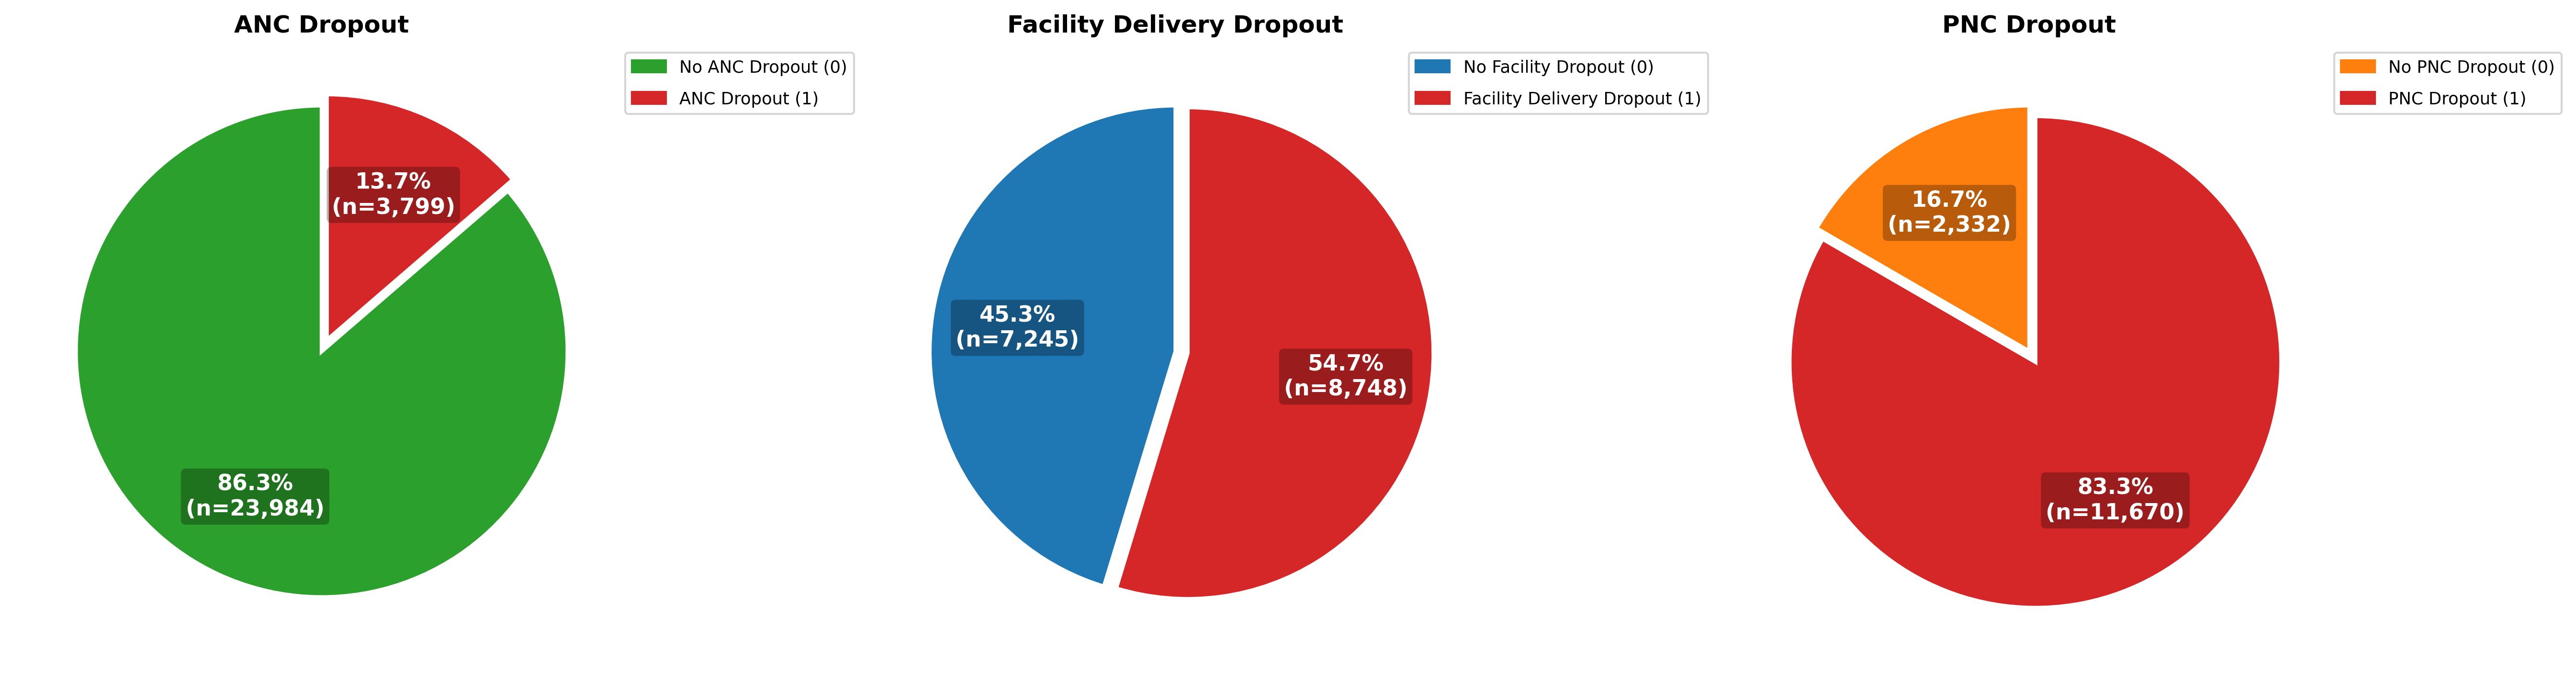

In [4]:
import matplotlib.patches as mpatches

outcome_info = {
    "anc_dropout":      (["#2ca02c","#d62728"], "ANC Dropout",
                         ["No ANC Dropout (0)", "ANC Dropout (1)"]),
    "facility_dropout": (["#1f77b4","#d62728"], "Facility Delivery Dropout",
                         ["No Facility Dropout (0)", "Facility Delivery Dropout (1)"]),
    "pnc_dropout":      (["#ff7f0e","#d62728"], "PNC Dropout",
                         ["No PNC Dropout (0)", "PNC Dropout (1)"]),
}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, outcome in zip(axes, OUTCOMES):
    colors, label, cat_labels = outcome_info[outcome]
    sub   = df[df[outcome].notna()]
    n_no  = int((sub[outcome] == 0).sum())
    n_drp = int(sub[outcome].sum())
    total = len(sub)

    wedges, texts, ats = ax.pie(
        [n_no, n_drp],
        labels=None,
        colors=colors,
        explode=[0, 0.05],
        autopct=lambda pct: f"{pct:.1f}%\n(n={int(pct/100*total):,})",
        startangle=90,
        pctdistance=0.65,
        wedgeprops={"edgecolor": "white", "linewidth": 2}
    )

    # Make slice labels clearly visible
    for at in ats:
        at.set_fontsize(11)
        at.set_fontweight("bold")
        at.set_color("white")
        at.set_bbox(dict(
            boxstyle="round,pad=0.22",
            facecolor="black",
            alpha=0.28,
            edgecolor="none"
        ))

    # Legend
    patches = [
        mpatches.Patch(color=colors[i], label=cat_labels[i])
        for i in range(2)
    ]
    ax.legend(handles=patches, loc="upper right", fontsize=8.5,
              frameon=True, bbox_to_anchor=(1.38, 1.0), labelspacing=0.9)
    ax.set_title(label, fontsize=12, fontweight="bold")

plt.tight_layout()
plt.savefig(f"{OUT}Figure1_Outcome_Distribution.png", dpi=300, bbox_inches="tight")
plt.show()

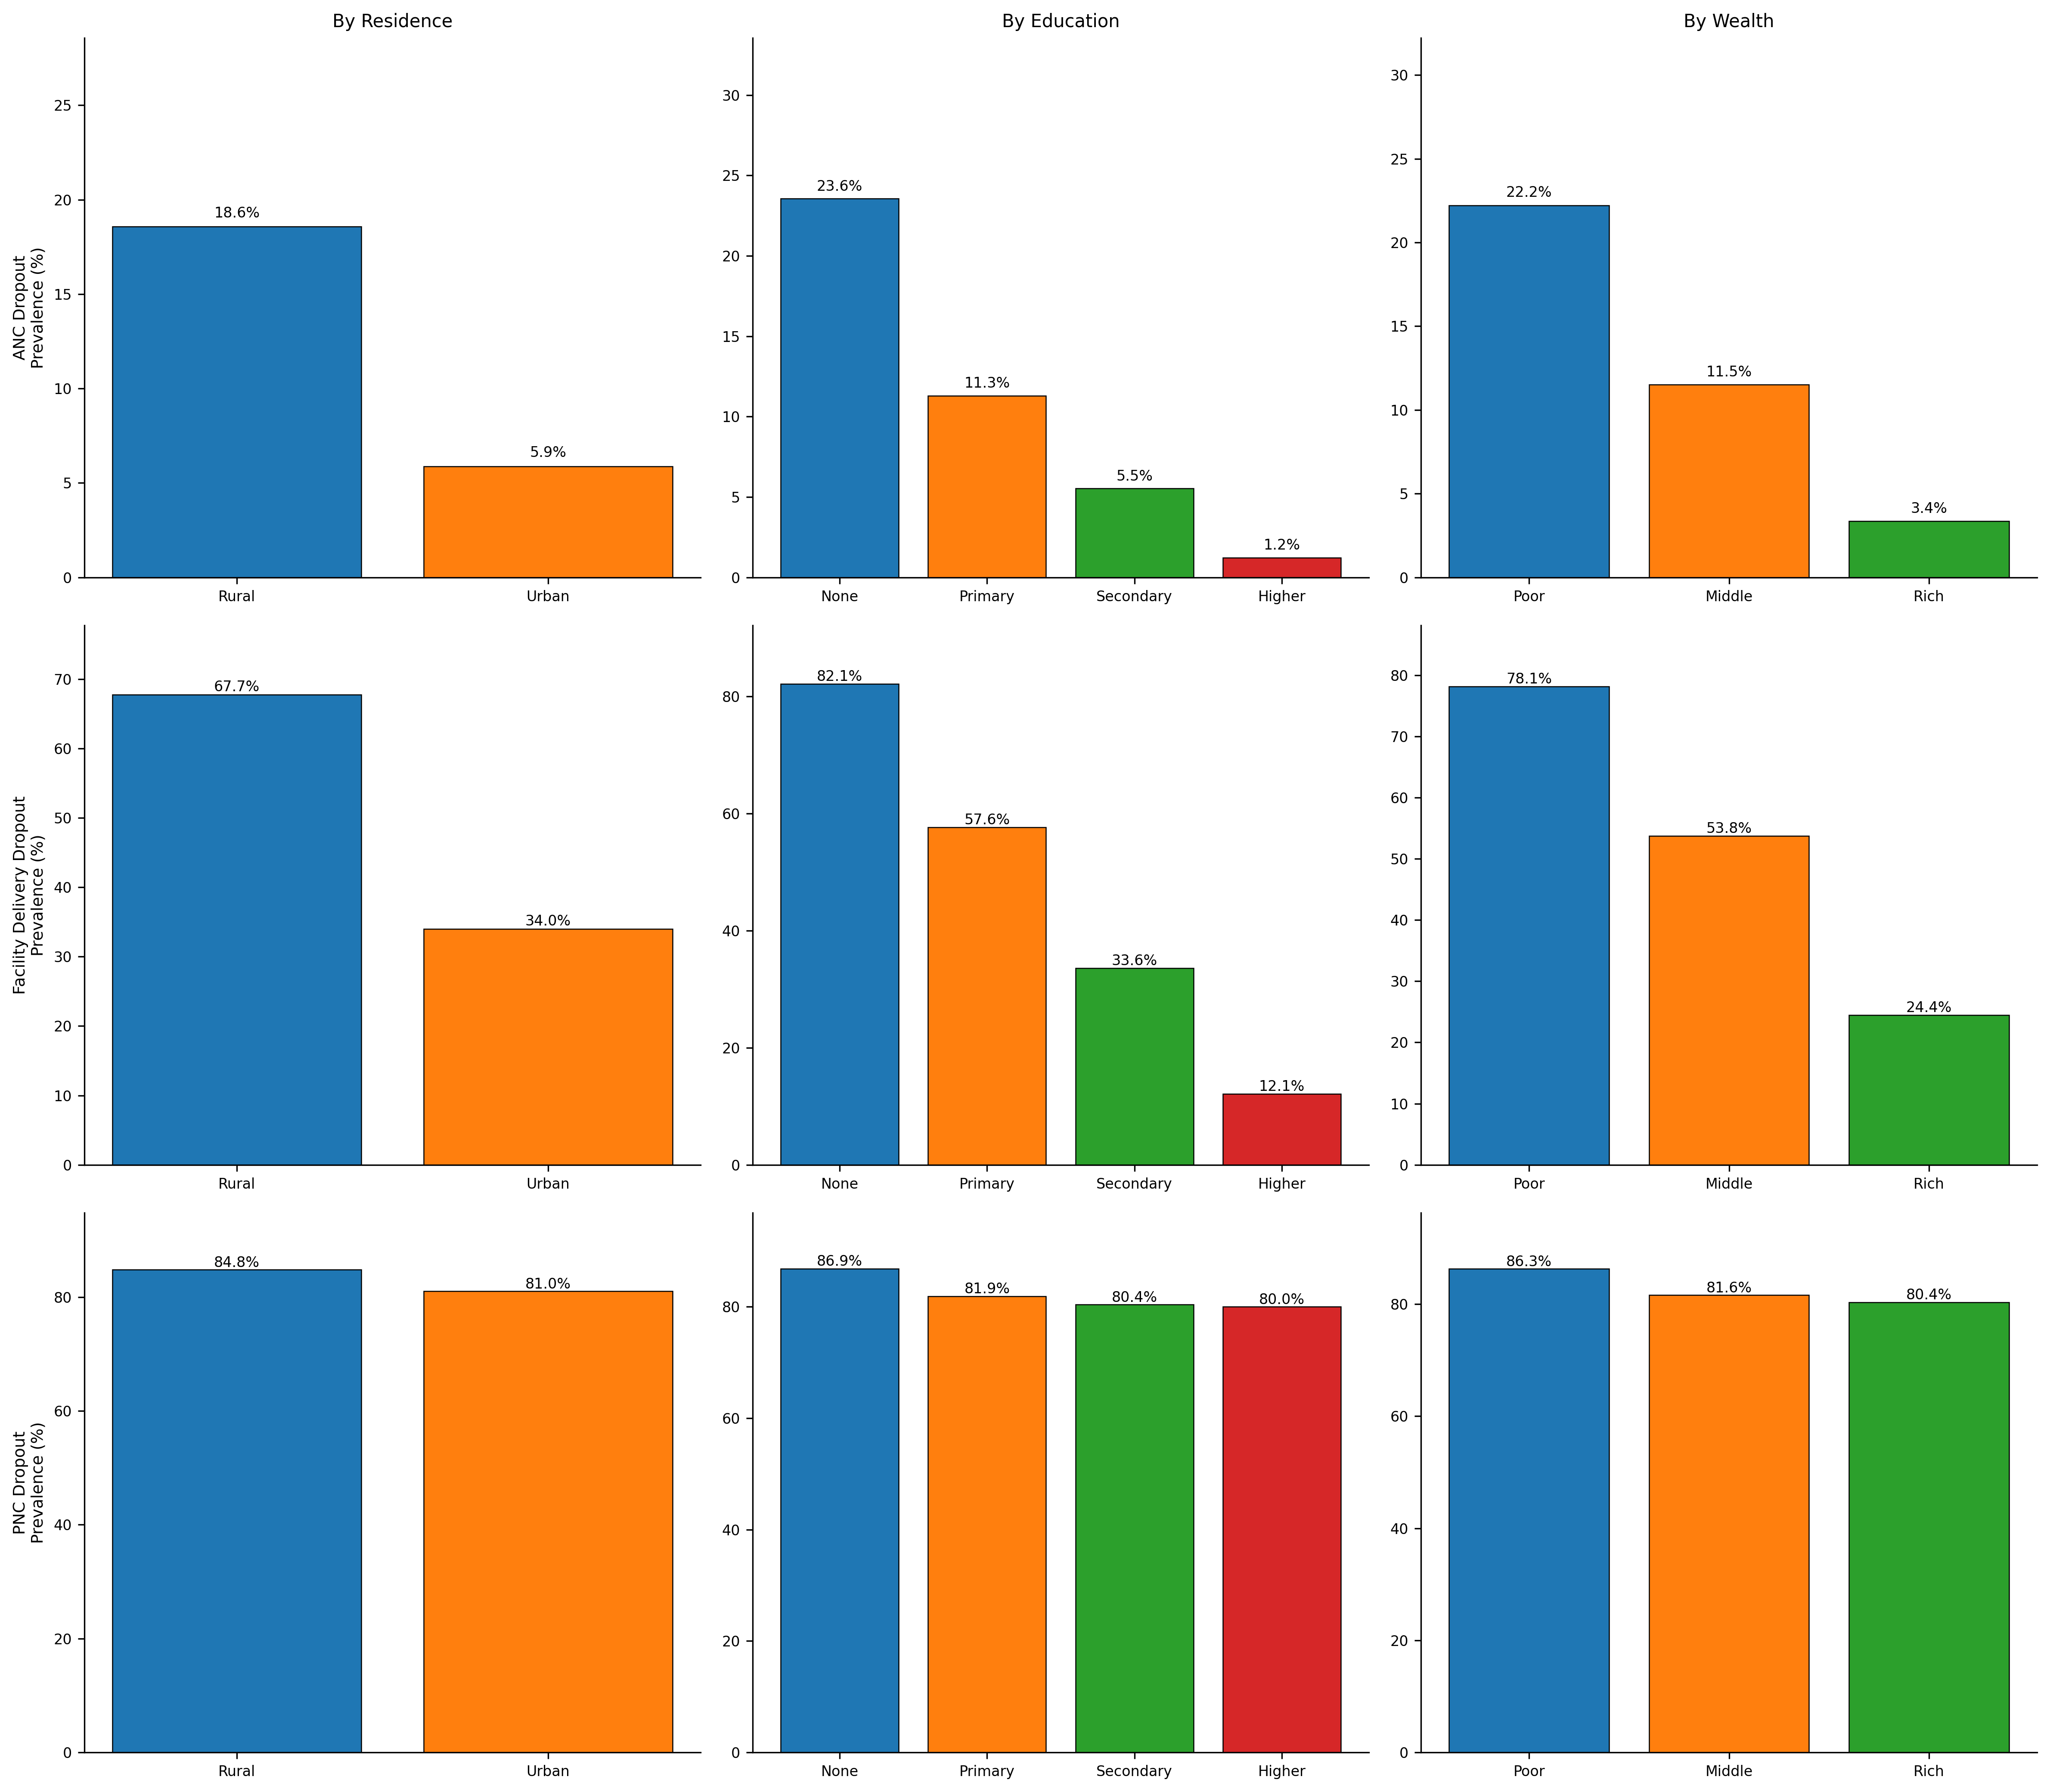

In [5]:
# FIGURE 2: Dropout Prevalence by Subgroups
PALETTE   = ["#1f77b4","#ff7f0e","#2ca02c","#d62728"]
subgroups = [
    ("By Residence",  "urban",             {0:"Rural",1:"Urban"}),
    ("By Education",  "mothers_education", {0:"None",1:"Primary",2:"Secondary",3:"Higher"}),
    ("By Wealth",     "wealth_cat",        {0:"Poor",1:"Middle",2:"Rich"}),
]
row_labels = ["ANC Dropout","Facility Delivery Dropout","PNC Dropout"]

fig, axes = plt.subplots(3, 3, figsize=(16, 14))
for row, outcome in enumerate(OUTCOMES):
    sub = df[df[outcome].notna()].copy()
    for col, (subtitle, var, labels) in enumerate(subgroups):
        ax  = axes[row][col]
        grp = sub.groupby(var)[outcome].mean() * 100
        grp.index = [labels.get(i, str(i)) for i in grp.index]
        bars = ax.bar(grp.index, grp.values,
                      color=PALETTE[:len(grp)],
                      edgecolor="black", linewidth=0.6)
        for bar, val in zip(bars, grp.values):
            ax.text(bar.get_x()+bar.get_width()/2,
                    bar.get_height()+0.5,
                    f"{val:.1f}%", ha="center", fontsize=8)
        if col == 0:
            ax.set_ylabel(f"{row_labels[row]}\nPrevalence (%)", fontsize=9)
        ax.set_title(subtitle if row==0 else "", fontsize=10)
        ax.set_ylim(0, grp.max()+10)
        ax.spines[["top","right"]].set_visible(False)
        ax.tick_params(labelsize=8)

plt.tight_layout()
plt.show()


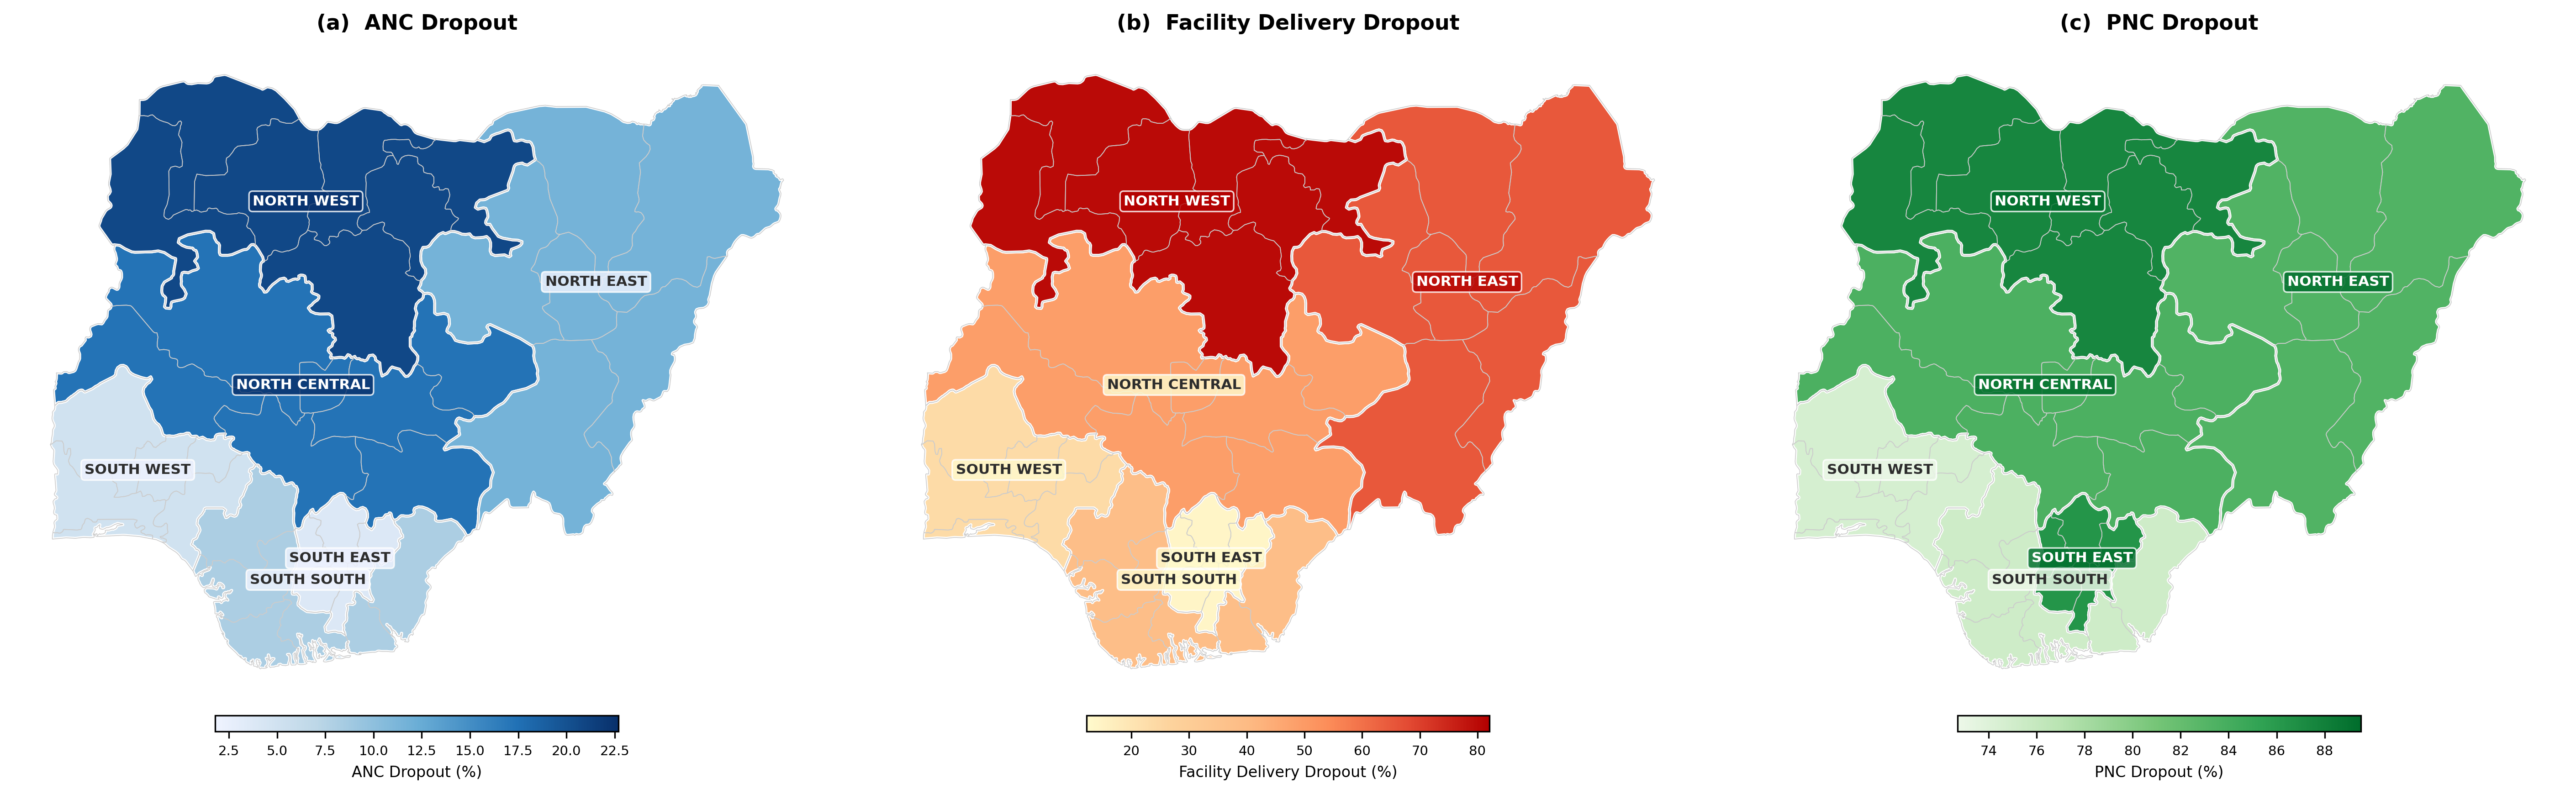

In [6]:
# FIGURE 3: Nigeria Regional Map
# FIGURE 3: Three Regional Maps — ANC, Facility Delivery, PNC Dropout
import geopandas as gpd, urllib.request
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap

url = ("https://raw.githubusercontent.com/nvkelso/natural-earth-vector"
       "/master/geojson/ne_10m_admin_1_states_provinces.geojson")
urllib.request.urlretrieve(url, "/content/ne_states.geojson")

ZONE_MAP = {
    "Kebbi":"North West","Sokoto":"North West","Zamfara":"North West",
    "Katsina":"North West","Kaduna":"North West","Kano":"North West",
    "Jigawa":"North West","Borno":"North East","Yobe":"North East",
    "Adamawa":"North East","Gombe":"North East","Bauchi":"North East",
    "Taraba":"North East","Niger":"North Central","Kwara":"North Central",
    "Kogi":"North Central","Benue":"North Central","Plateau":"North Central",
    "Nassarawa":"North Central","Federal Capital Territory":"North Central",
    "Anambra":"South East","Enugu":"South East","Abia":"South East",
    "Ebonyi":"South East","Imo":"South East","Rivers":"South South",
    "Bayelsa":"South South","Delta":"South South","Cross River":"South South",
    "Akwa Ibom":"South South","Edo":"South South","Lagos":"South West",
    "Ogun":"South West","Oyo":"South West","Osun":"South West",
    "Ondo":"South West","Ekiti":"South West",
}
CODE_ZONE = {1:"North West",2:"North East",3:"North Central",
             4:"South East",5:"South South",6:"South West"}
SHORT_NAMES = {
    "North West":"NORTH WEST","North East":"NORTH EAST",
    "North Central":"NORTH CENTRAL","South East":"SOUTH EAST",
    "South South":"SOUTH SOUTH","South West":"SOUTH WEST",
}

# Compute dropout rates by zone
df_zone = df_raw[["v024","m14","m15","m70","v005"]].copy()
df_zone.rename(columns={"v024":"zone_code","v005":"weight"}, inplace=True)
df_zone["weight"]           = df_zone["weight"] / 1e6
df_zone["anc_dropout"]      = np.where(df_zone["m14"]==0, 1, 0)
df_zone["facility_dropout"] = df_zone["m15"].apply(
    lambda x: 0 if (pd.notna(x) and 20<=x<40) else (1 if pd.notna(x) else np.nan))
df_zone["pnc_dropout"]      = df_zone["m70"].apply(
    lambda x: 1 if (pd.notna(x) and x==0) else (0 if (pd.notna(x) and x==1) else np.nan))

zone_data = {}
for code, zone_name in CODE_ZONE.items():
    zdf = df_zone[df_zone["zone_code"]==code]
    if len(zdf) > 0:
        zone_data[zone_name] = {
            "anc": round(zdf["anc_dropout"].mean()*100, 1),
            "fac": round(zdf["facility_dropout"].mean()*100, 1),
            "pnc": round(zdf["pnc_dropout"].mean()*100, 1),
        }

# Load and dissolve shapefile
gdf = gpd.read_file("/content/ne_states.geojson")
nga = gdf[gdf["admin"]=="Nigeria"].copy()
nga["zone"] = nga["name"].map(ZONE_MAP)
nga = nga[nga["zone"].notna()].copy()
nga_zones = nga.dissolve(by="zone").reset_index()

# Map config: one entry per outcome
MAP_CONFIG = [
    {
        "key":        "anc",
        "title":      "(a)  ANC Dropout",
        "cbar_label": "ANC Dropout (%)",
        "cmap":       LinearSegmentedColormap.from_list(
                          "anc",["#EFF3FF","#BDD7E7","#6BAED6","#2171B5","#08306B"],N=256),
        "thresh":     15,
        "dark_box":   "#08306B",
        "light_box":  "#EFF3FF",
    },
    {
        "key":        "fac",
        "title":      "(b)  Facility Delivery Dropout",
        "cbar_label": "Facility Delivery Dropout (%)",
        "cmap":       LinearSegmentedColormap.from_list(
                          "fac",["#FFFACD","#FDD49E","#FDBB84","#FC8D59","#E34A33","#B30000"],N=256),
        "thresh":     55,
        "dark_box":   "#B30000",
        "light_box":  "#FFFACD",
    },
    {
        "key":        "pnc",
        "title":      "(c)  PNC Dropout",
        "cbar_label": "PNC Dropout (%)",
        "cmap":       LinearSegmentedColormap.from_list(
                          "pnc",["#EDF8E9","#BAE4B3","#74C476","#31A354","#006D2C"],N=256),
        "thresh":     82,
        "dark_box":   "#006D2C",
        "light_box":  "#EDF8E9",
    },
]

# Plot three maps side by side
fig, axes = plt.subplots(1, 3, figsize=(24, 8))
fig.subplots_adjust(wspace=0.08)

for ax, cfg in zip(axes, MAP_CONFIG):
    key = cfg["key"]
    nga_zones["_val"] = nga_zones["zone"].map(
        lambda z: zone_data.get(z, {}).get(key, np.nan))

    vmin = nga_zones["_val"].min() - 2
    vmax = nga_zones["_val"].max() + 2
    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)

    nga_zones.plot(column="_val", cmap=cfg["cmap"], norm=norm, ax=ax,
                   edgecolor="white", linewidth=1.5,
                   missing_kwds={"color":"lightgrey"})
    nga.plot(ax=ax, facecolor="none", edgecolor="#CCCCCC", linewidth=0.4)

    # Region name ONLY — no stats
    for _, row in nga_zones.iterrows():
        centroid  = row.geometry.centroid
        zone_name = row["zone"]
        val       = zone_data.get(zone_name, {}).get(key, 0)
        short     = SHORT_NAMES.get(zone_name, zone_name.upper())
        ax.annotate(
            short,
            xy=(centroid.x, centroid.y),
            ha="center", va="center",
            fontsize=7.5, fontweight="bold",
            color="white" if val > cfg["thresh"] else "#2d2d2d",
            bbox=dict(
                boxstyle="round,pad=0.25",
                facecolor=cfg["dark_box"] if val > cfg["thresh"] else cfg["light_box"],
                alpha=0.82, edgecolor="white", linewidth=0.8,
            )
        )

    # Colorbar
    sm = cm.ScalarMappable(cmap=cfg["cmap"], norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, shrink=0.50, pad=0.02,
                        orientation="horizontal", fraction=0.03, aspect=25)
    cbar.set_label(cfg["cbar_label"], fontsize=8)
    cbar.ax.tick_params(labelsize=7)

    ax.set_axis_off()
    ax.set_title(cfg["title"], fontsize=11, fontweight="bold", pad=8)

plt.savefig(f"{OUT}Figure3_Regional_Maps.png", dpi=300, bbox_inches="tight")
plt.show()

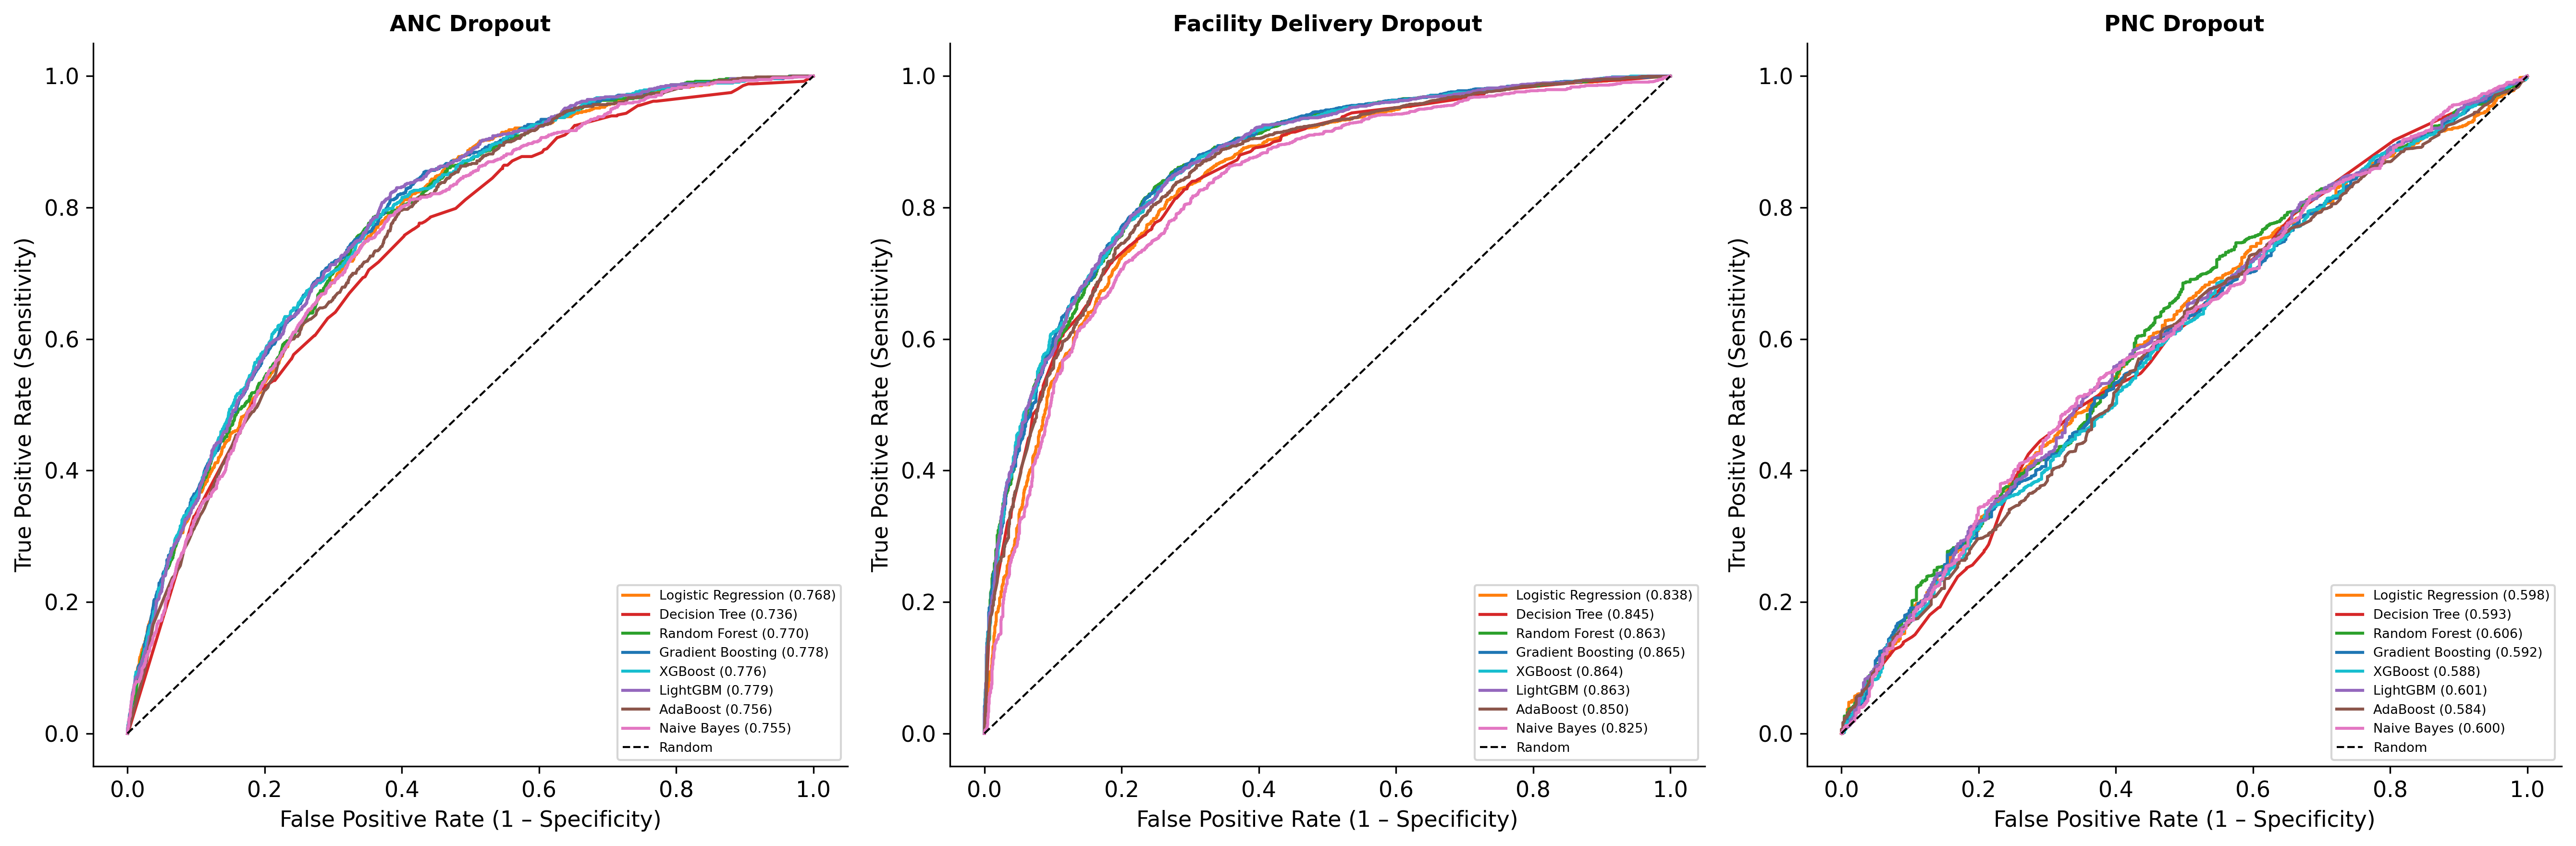

In [7]:
#FIGURE 4: ROC Curves (3 subplots)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, outcome in zip(axes, OUTCOMES):
    y_test = all_splits[outcome]["y_test"]
    for (name,_,_,_), color in zip(MODELS_DEF, COLORS_8):
        fpr, tpr, _ = roc_curve(y_test,
                                 all_results[outcome][name]["yprob"])
        auc_val = all_results[outcome][name]["auc"]
        ax.plot(fpr, tpr,
                label=f"{name} ({auc_val:.3f})",
                color=color, linewidth=1.5)
    ax.plot([0,1],[0,1], "k--", linewidth=1, label="Random")
    ax.set_xlabel("False Positive Rate (1 – Specificity)")
    ax.set_ylabel("True Positive Rate (Sensitivity)")
    ax.set_title(OUTCOME_LABELS[outcome],
                 fontsize=11, fontweight="bold")
    ax.legend(loc="lower right", fontsize=6.5)
    ax.spines[["top","right"]].set_visible(False)

plt.tight_layout()
plt.show()

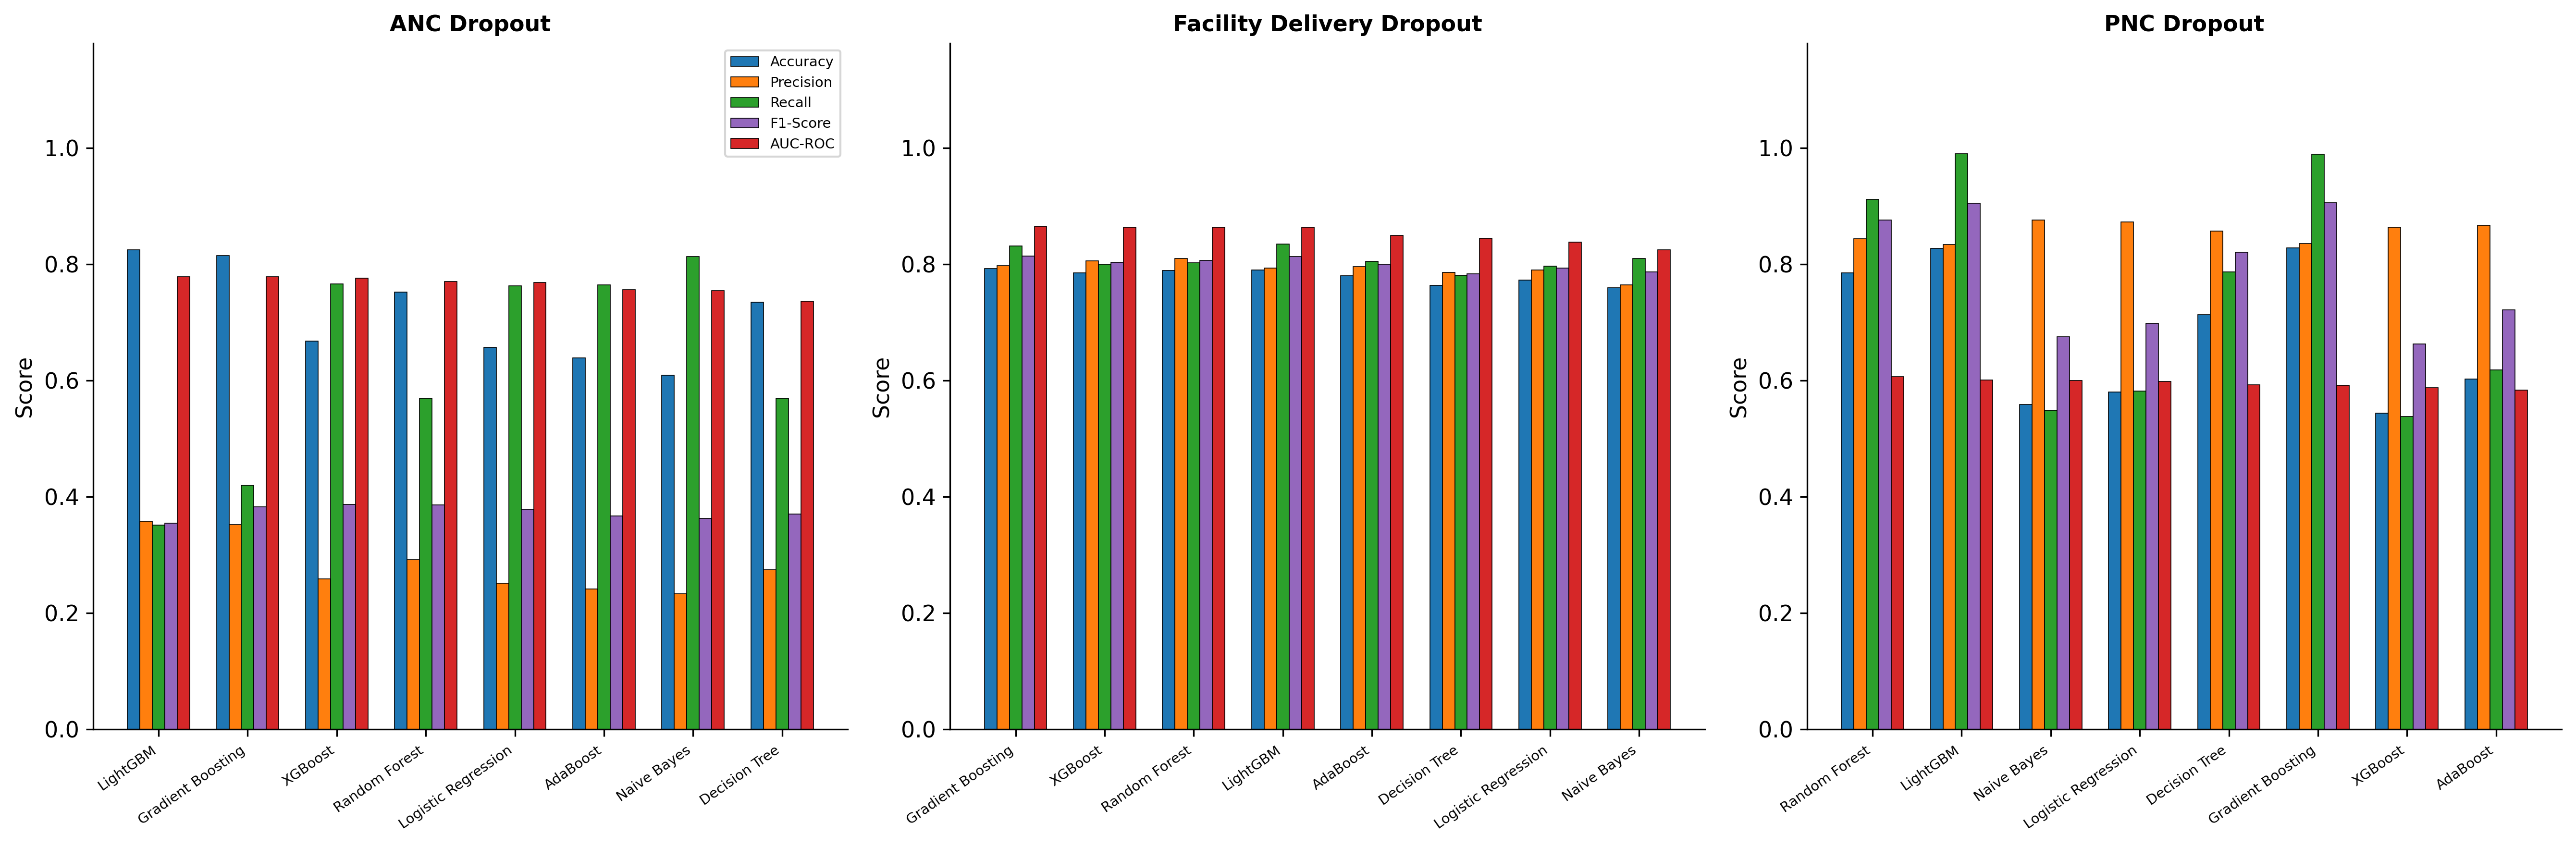

In [8]:
# FIGURE 5: Performance Metrics Comparison (3 subplots)
metric_list = ["Accuracy","Precision","Recall","F1-Score","AUC-ROC"]
mc          = ["#1f77b4","#ff7f0e","#2ca02c","#9467bd","#d62728"]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, outcome in zip(axes, OUTCOMES):
    mdf = pd.DataFrame({n:{
        "Accuracy": v["acc"], "Precision": v["prec"],
        "Recall":   v["rec"], "F1-Score":  v["f1"],
        "AUC-ROC":  v["auc"]
    } for n,v in all_results[outcome].items()
    }).T.sort_values("AUC-ROC", ascending=False)

    mp = mdf[metric_list]
    x  = np.arange(len(mp)); w = 0.14
    for i,(m,c) in enumerate(zip(metric_list, mc)):
        ax.bar(x+i*w, mp[m], w, label=m,
               color=c, edgecolor="black", linewidth=0.4)
    ax.set_xticks(x+w*2)
    ax.set_xticklabels(mp.index, rotation=35,
                       ha="right", fontsize=7)
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1.18)
    ax.set_title(OUTCOME_LABELS[outcome],
                 fontsize=11, fontweight="bold")
    if outcome == OUTCOMES[0]:
        ax.legend(loc="upper right", fontsize=7)
    ax.spines[["top","right"]].set_visible(False)

plt.tight_layout()
plt.show()

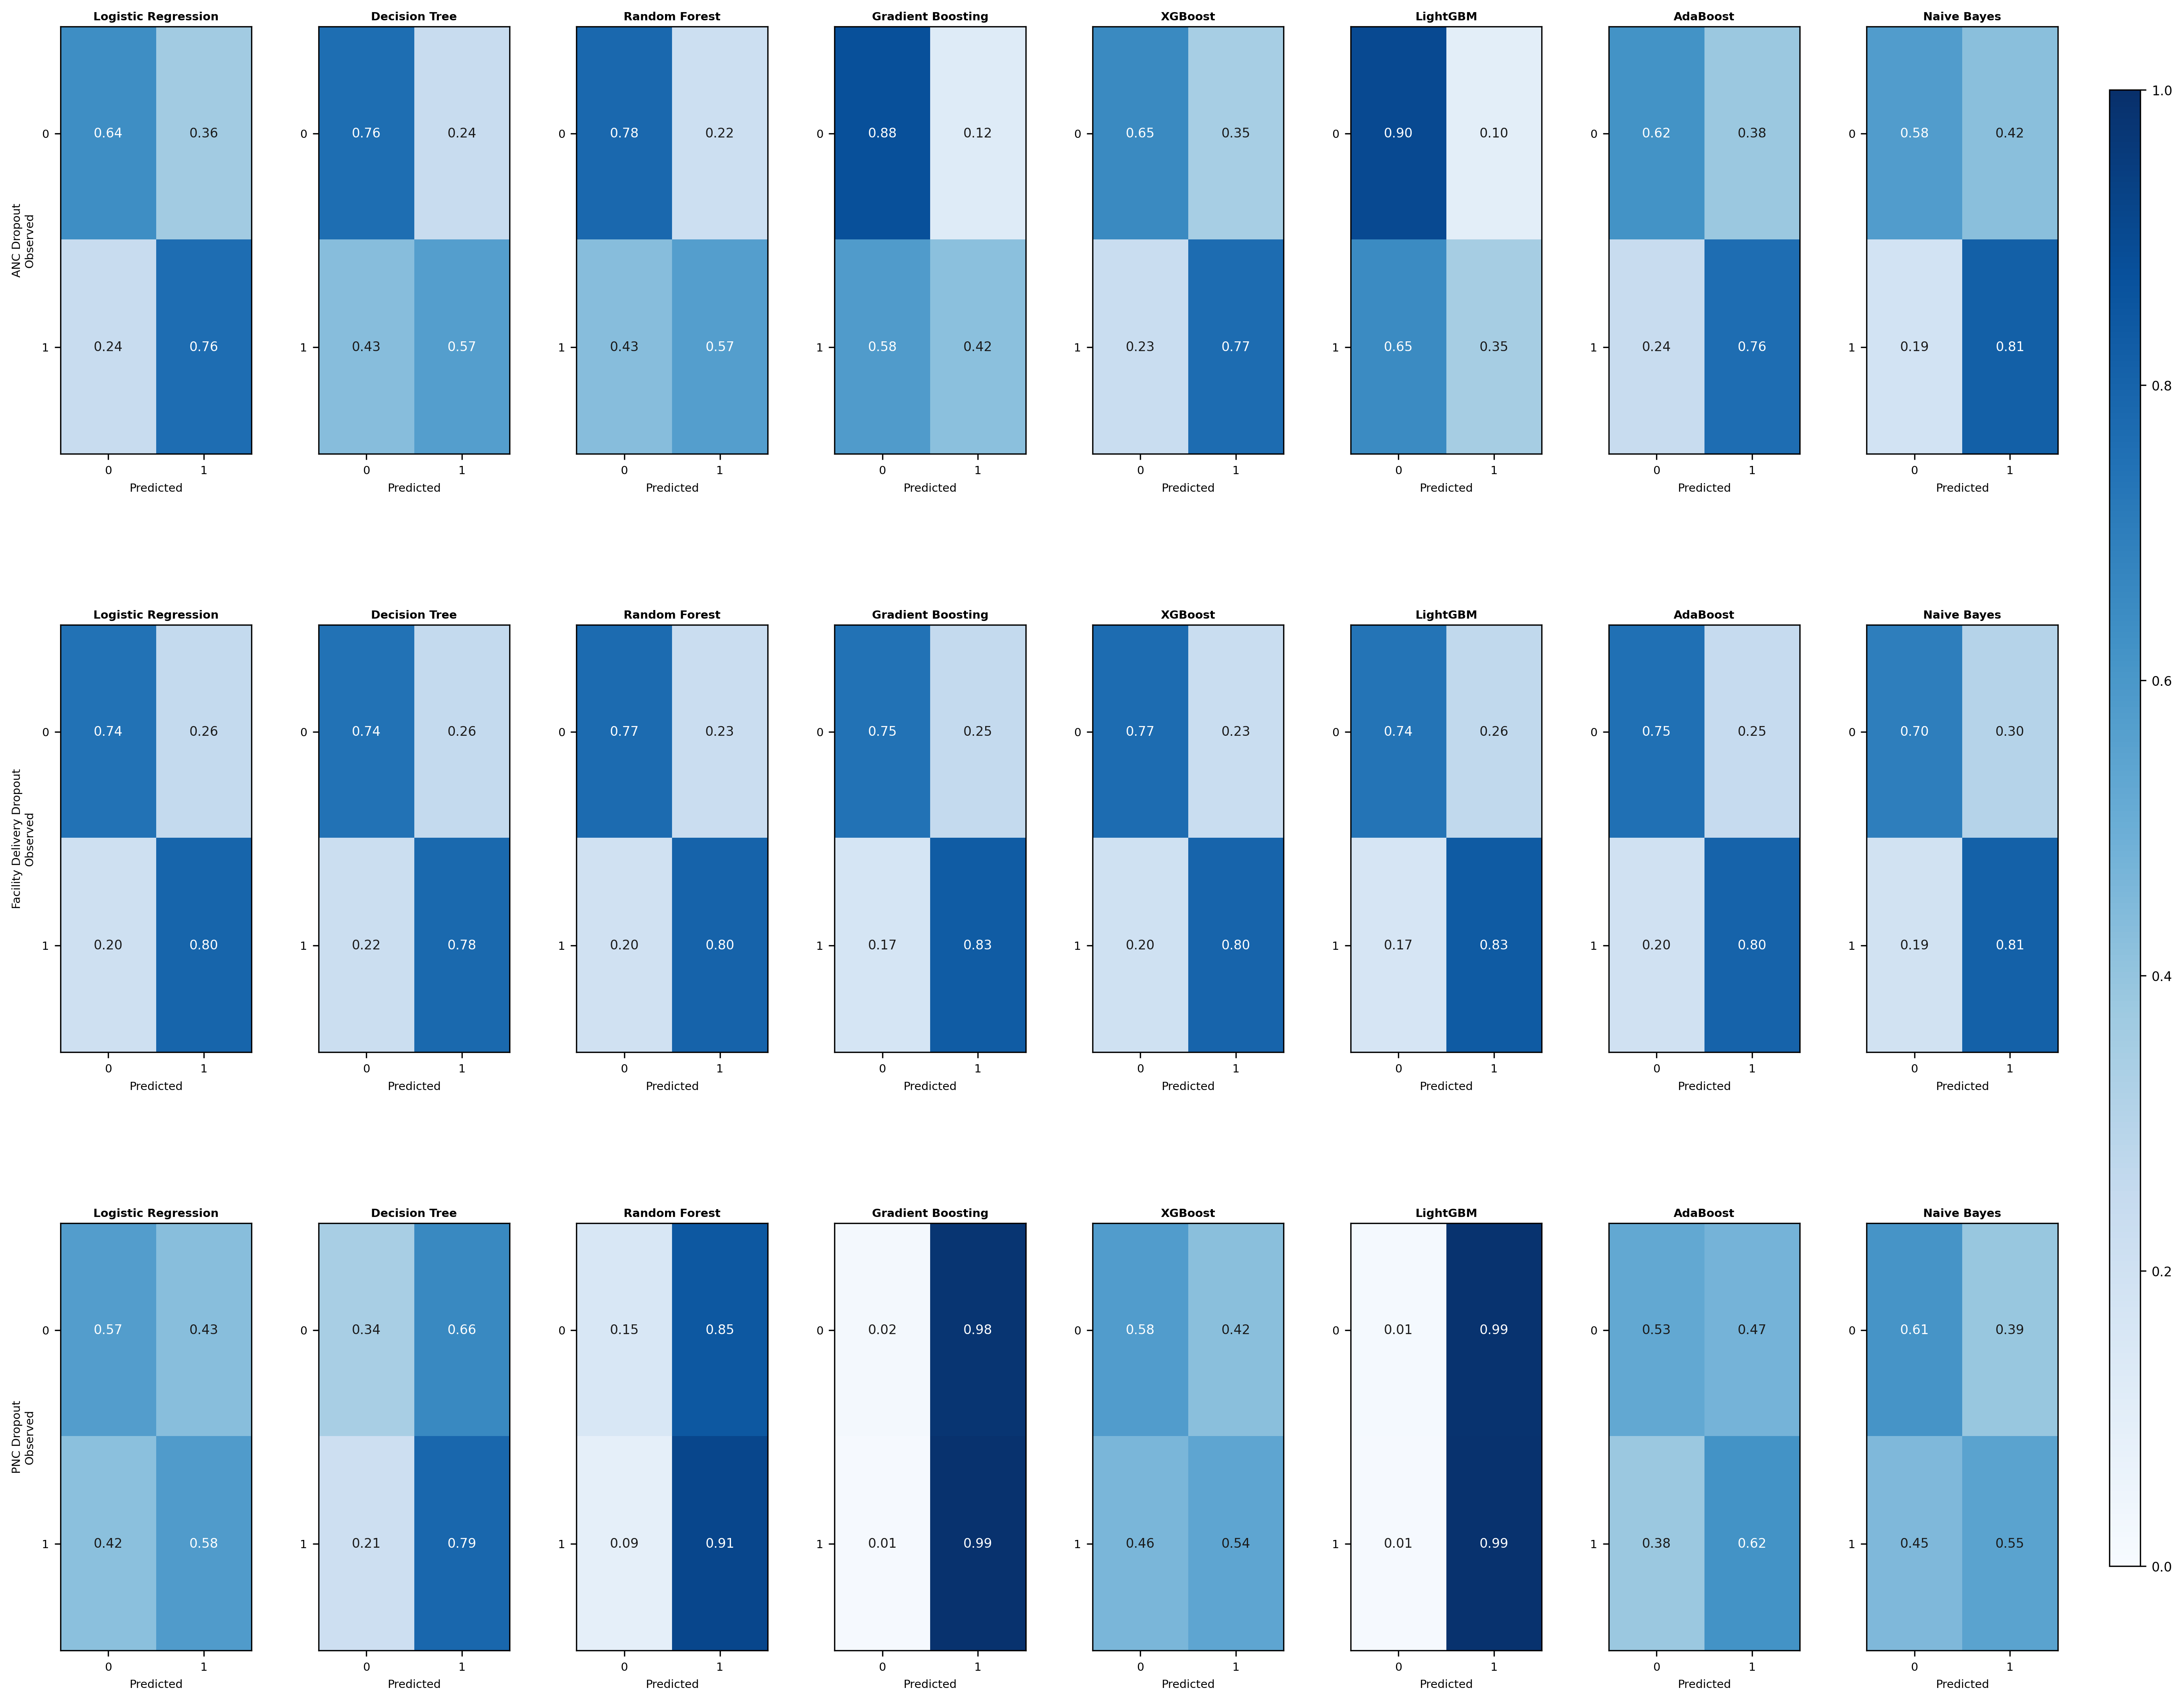

In [9]:
# FIGURE 6: Normalized Confusion Matrices (3 rows × 8 models)
CMAP       = "Blues"
VMIN, VMAX = 0.0, 1.0
norm_cm    = mcolors.Normalize(vmin=VMIN, vmax=VMAX)

fig = plt.figure(figsize=(22, 18))
fig.subplots_adjust(hspace=0.40, wspace=0.35)
sm  = plt.cm.ScalarMappable(cmap=CMAP, norm=norm_cm)
sm.set_array([])

for o_idx, outcome in enumerate(OUTCOMES):
    y_test = all_splits[outcome]["y_test"]
    for m_idx, (name,_,_,_) in enumerate(MODELS_DEF):
        ax     = fig.add_subplot(3, 8, o_idx*8 + m_idx + 1)
        cm_raw = all_results[outcome][name]["cm"]
        cm_n   = cm_raw.astype(float) / cm_raw.sum(axis=1, keepdims=True)
        ax.imshow(cm_n, cmap=CMAP, vmin=VMIN, vmax=VMAX, aspect="auto")
        for r in range(2):
            for c in range(2):
                val = cm_n[r, c]
                ax.text(c, r, f"{val:.2f}",
                        ha="center", va="center", fontsize=8,
                        color="white" if val>0.55 else "#1a1a1a")
        ax.set_xticks([0,1])
        ax.set_xticklabels(["0","1"], fontsize=7)
        ax.set_yticks([0,1])
        ax.set_yticklabels(["0","1"], fontsize=7)
        ax.set_xlabel("Predicted", fontsize=7)
        if m_idx == 0:
            ax.set_ylabel(
                f"{OUTCOME_LABELS[outcome]}\nObserved",
                fontsize=7)
        else:
            ax.set_ylabel("")
        ax.set_title(name, fontsize=7, fontweight="bold", pad=4)

cbar_ax = fig.add_axes([0.92, 0.15, 0.012, 0.7])
cbar    = fig.colorbar(sm, cax=cbar_ax)
cbar.set_ticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
cbar.ax.tick_params(labelsize=8)
plt.show()

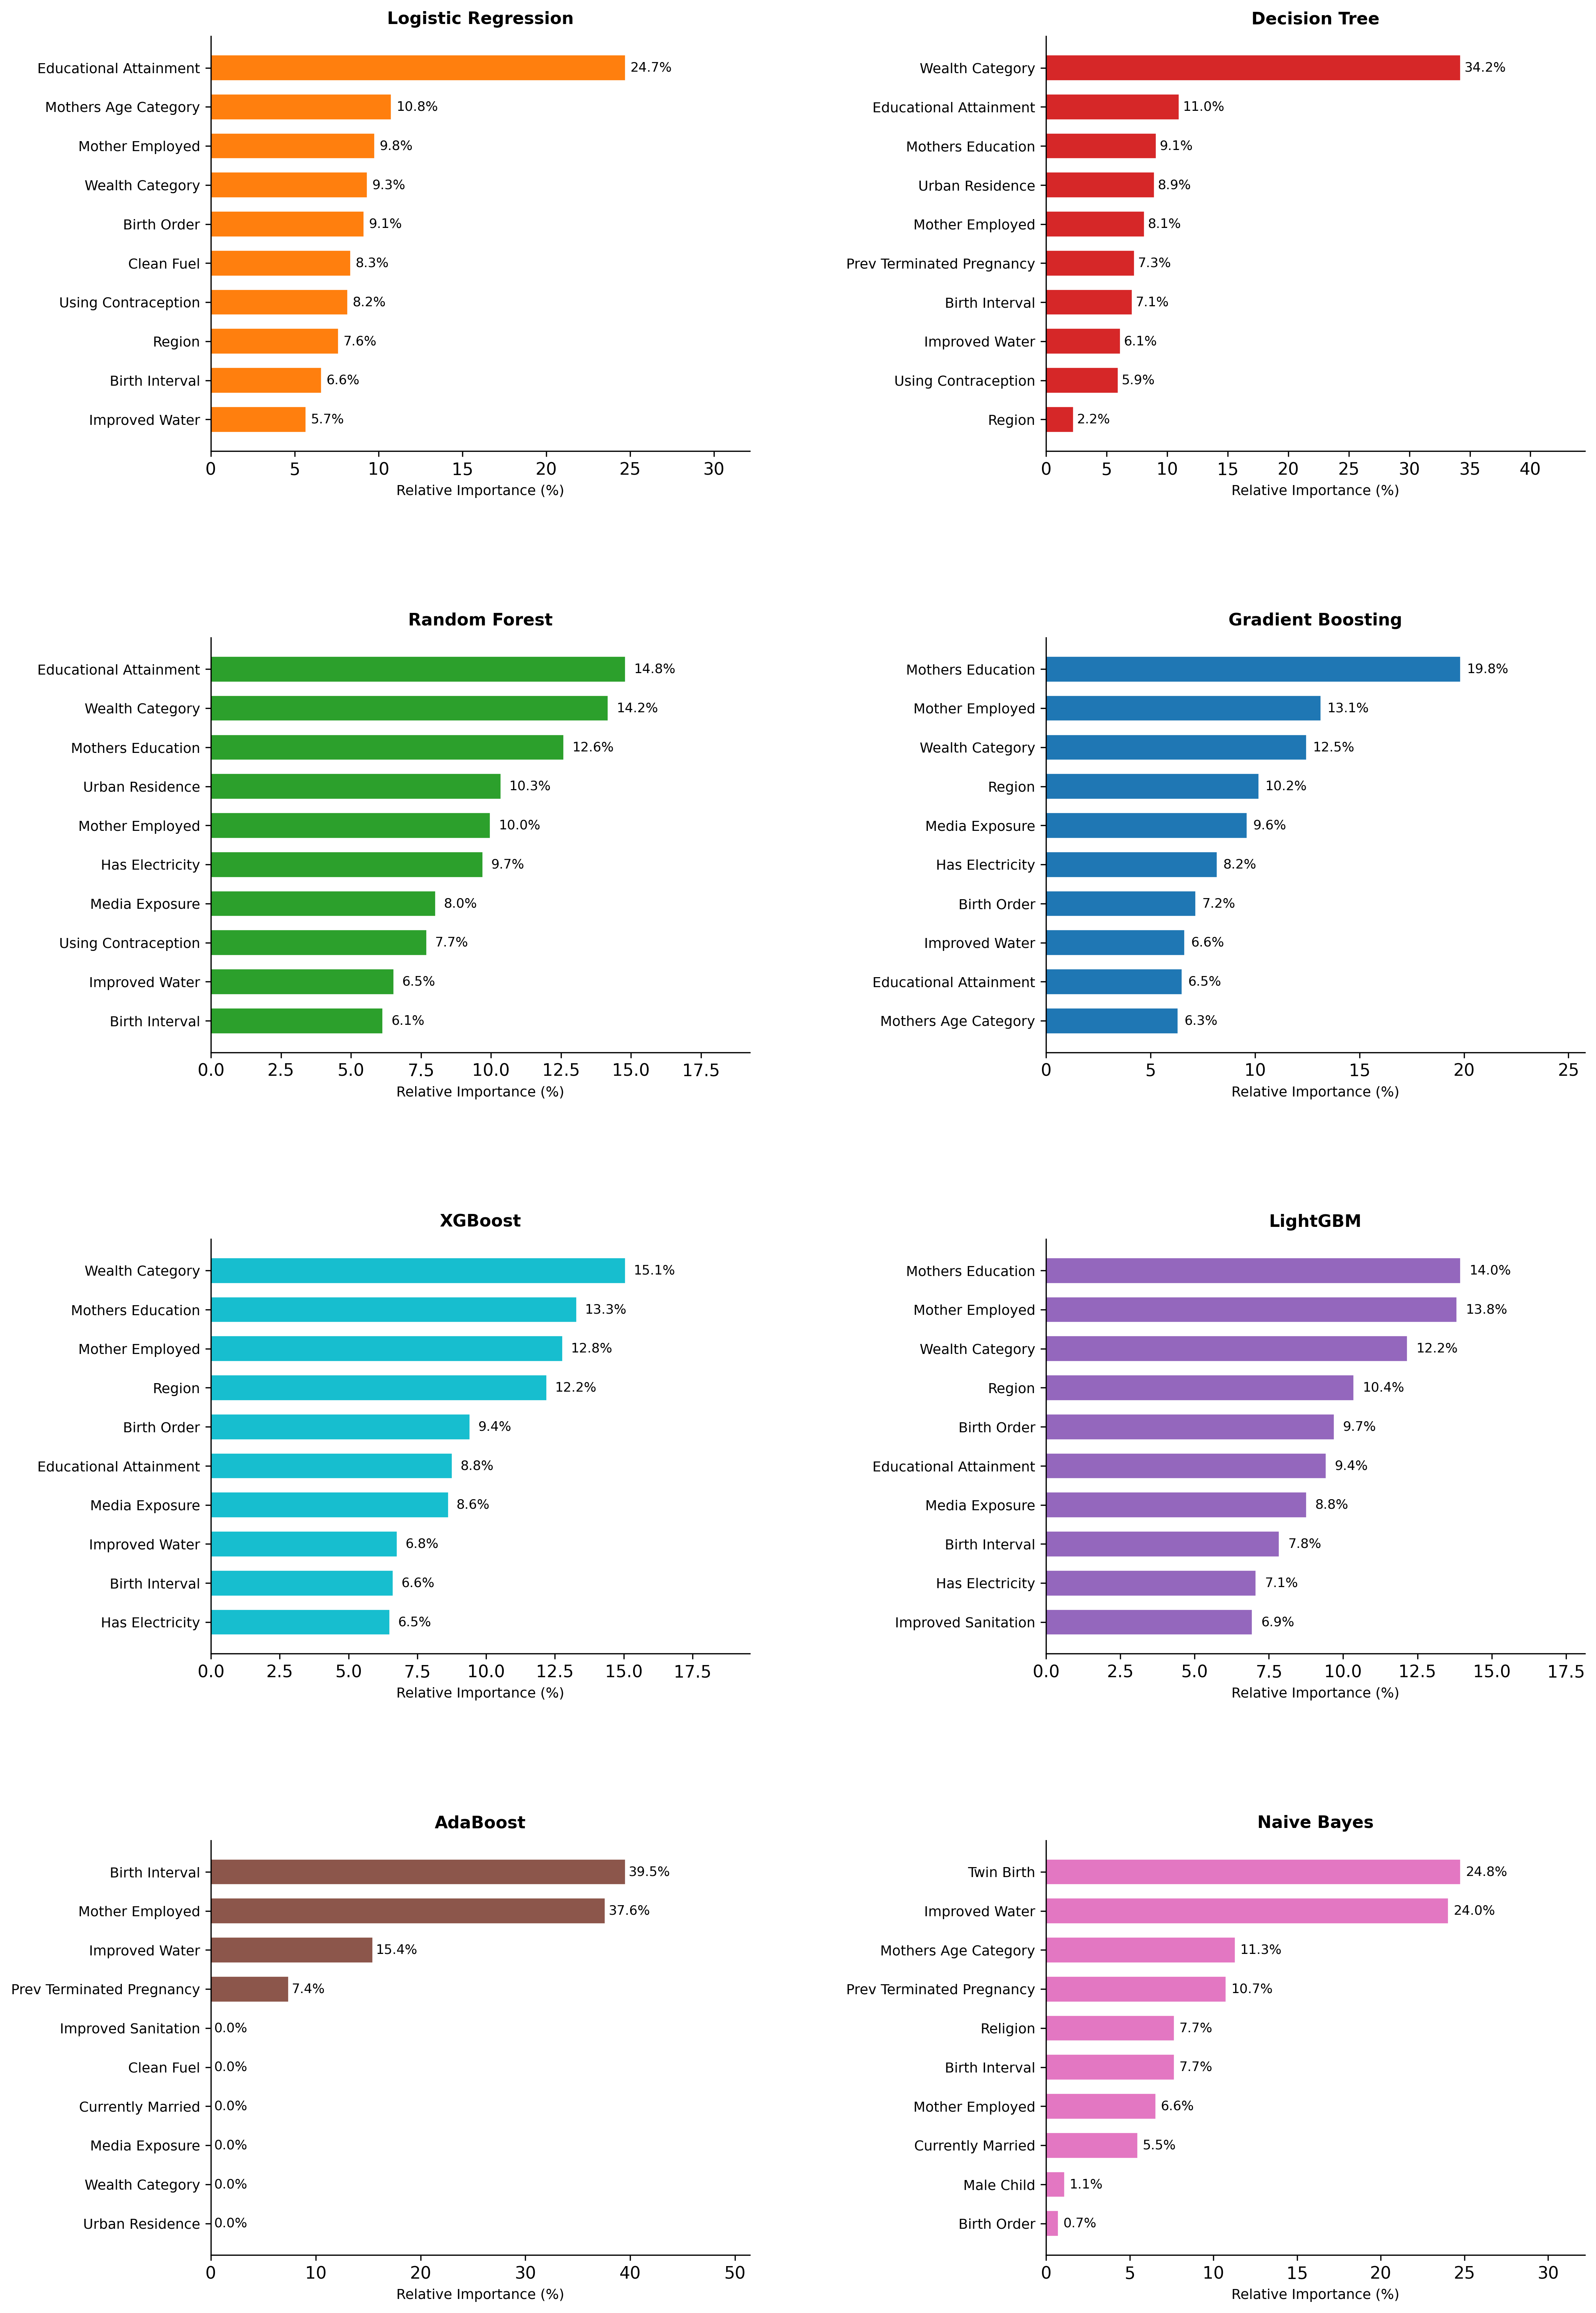

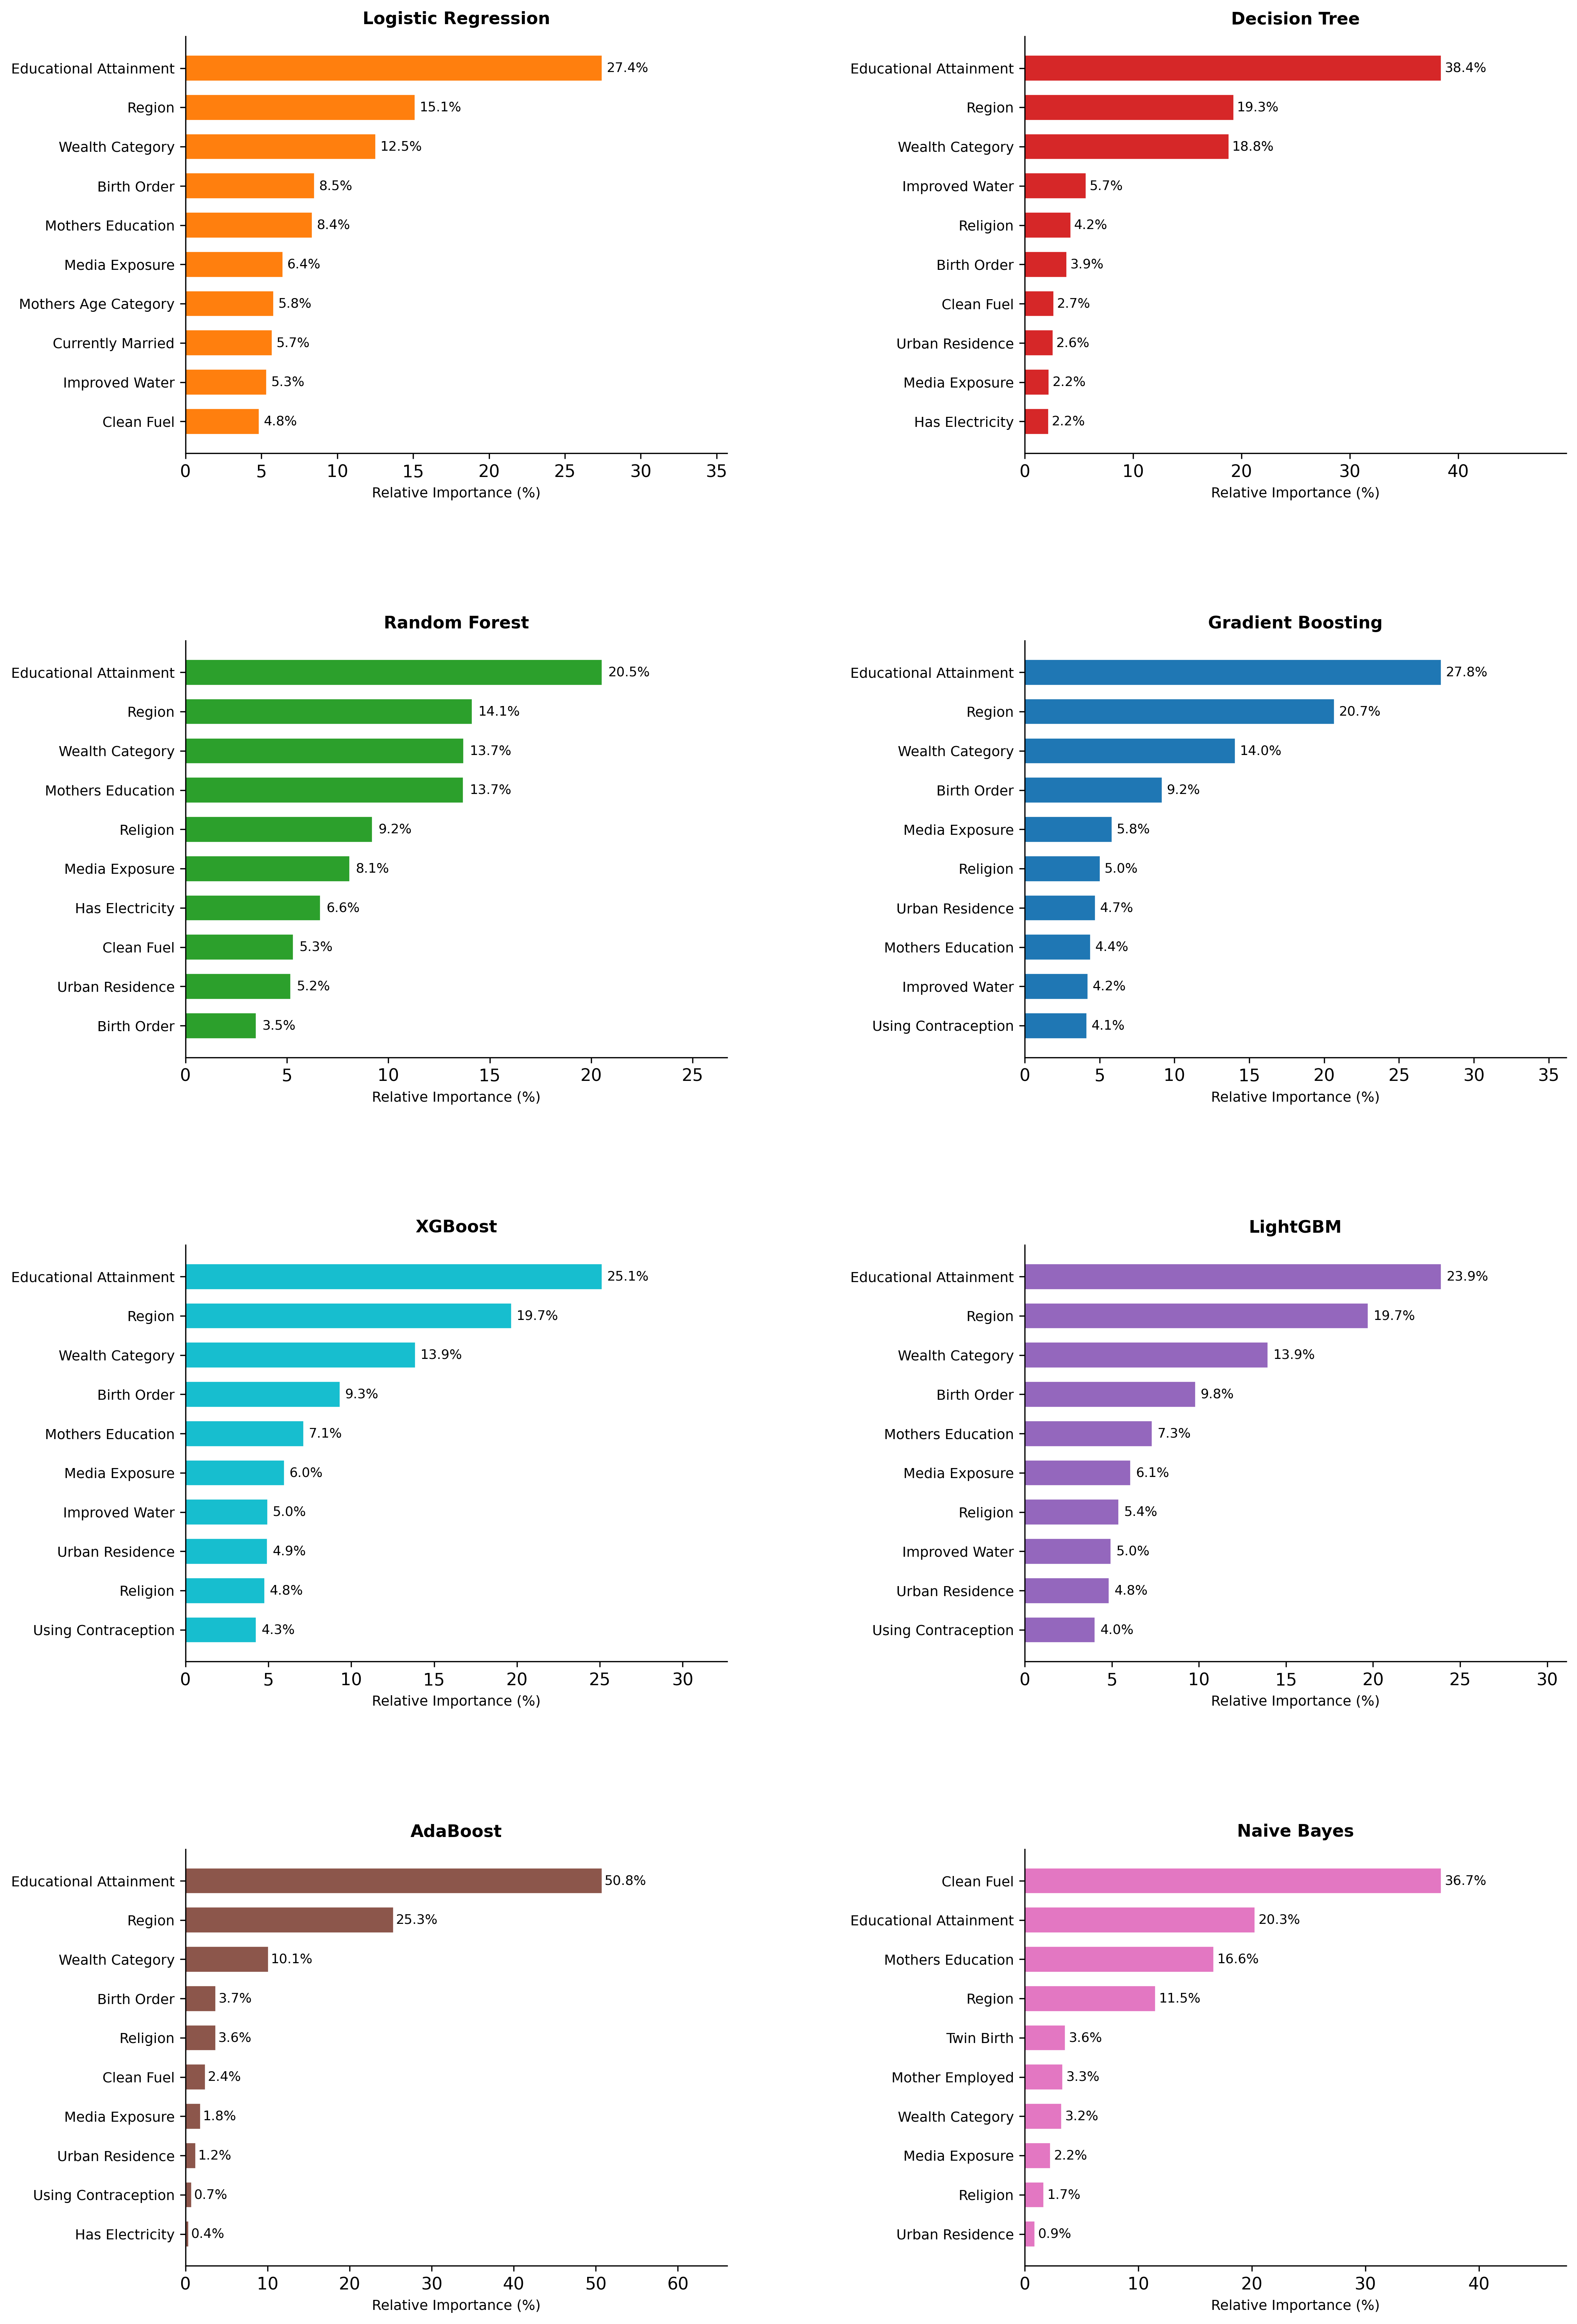

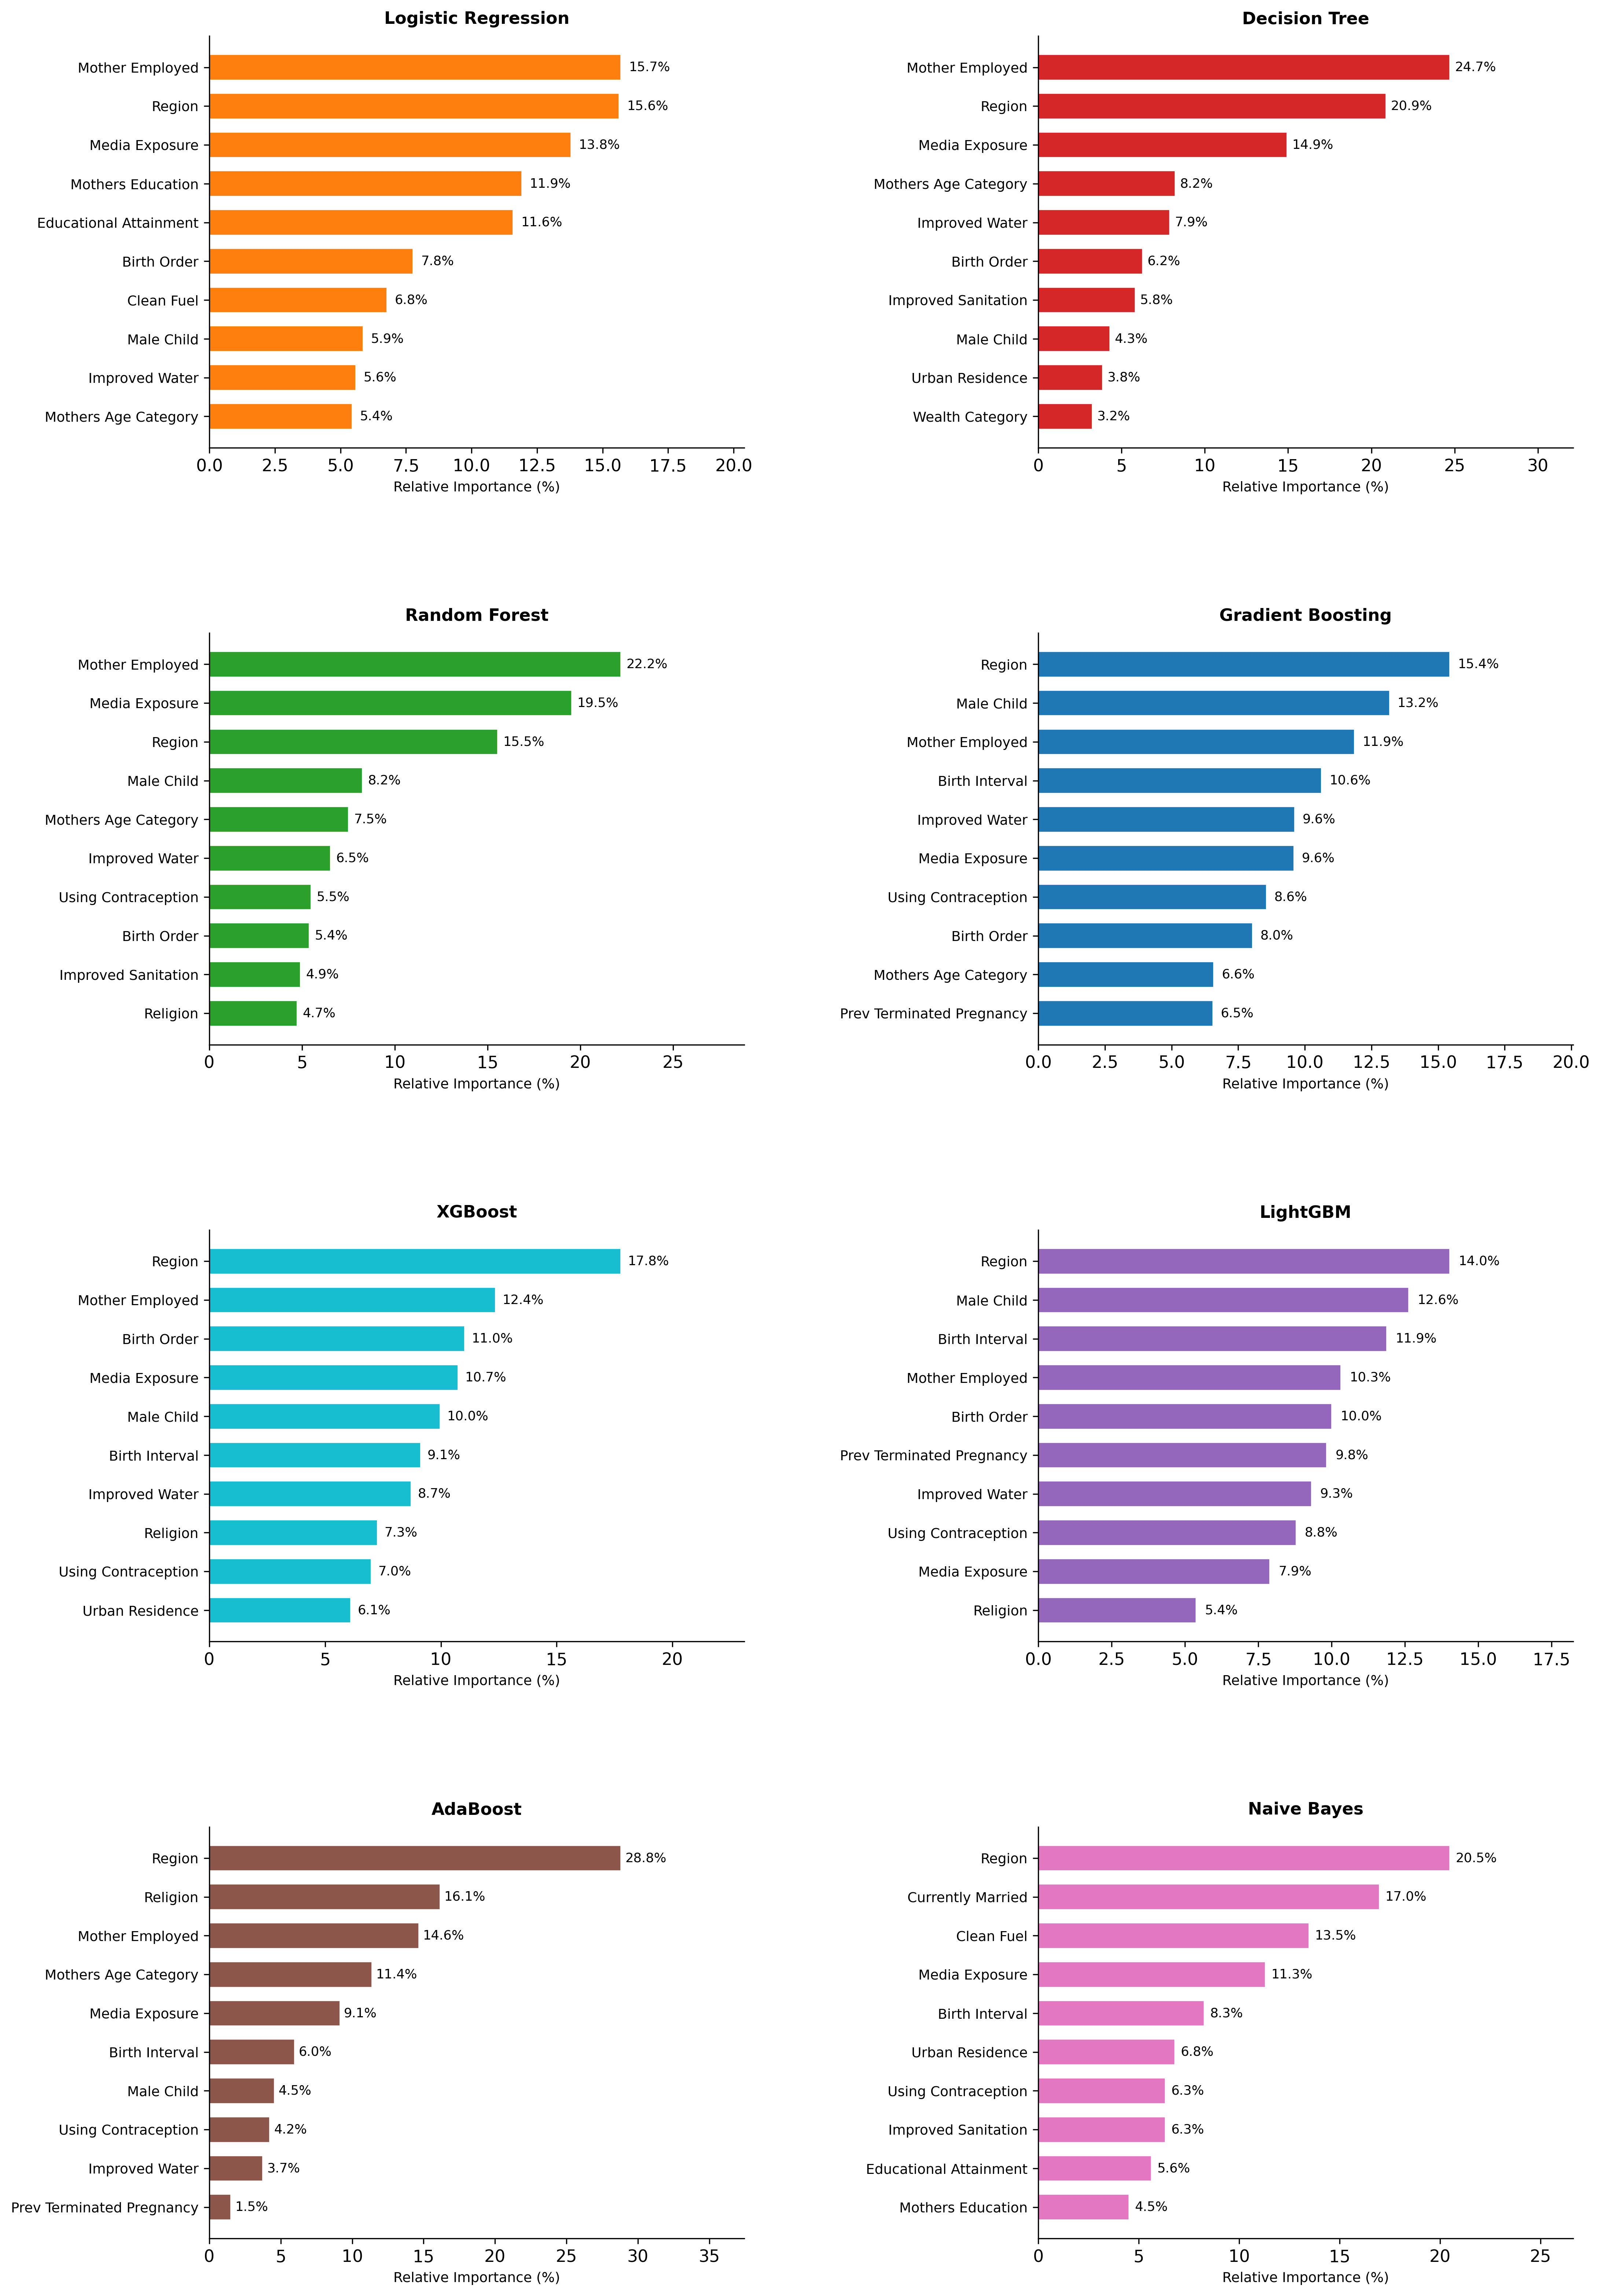

In [10]:
# FIGURE 7: Feature Importance 4×2 Panel (one figure per outcome)
TOP_N = 10

for outcome in OUTCOMES:
    fig = plt.figure(figsize=(16, 26))
    fig.subplots_adjust(hspace=0.45, wspace=0.55)

    for idx, (name,_,_,color) in enumerate(MODELS_DEF):
        ax  = fig.add_subplot(4, 2, idx+1)
        imp = all_importance[outcome][name]

        sorted_idx = np.argsort(imp)[::-1][:TOP_N]
        top_labels = [renamed_cols[i] for i in sorted_idx]
        top_vals   = imp[sorted_idx]
        total      = top_vals.sum()
        pct        = (top_vals/total*100) if total>0 else top_vals*100

        bars = ax.barh(range(TOP_N), list(pct[::-1]),
                       color=color, edgecolor="white",
                       linewidth=0.4, height=0.65)
        for bar, val in zip(bars, pct[::-1]):
            ax.text(bar.get_width()+0.3,
                    bar.get_y()+bar.get_height()/2,
                    f"{val:.1f}%", va="center",
                    ha="left", fontsize=8.5)
        ax.set_yticks(range(TOP_N))
        ax.set_yticklabels(top_labels[::-1], fontsize=9)
        ax.set_title(name, fontsize=11, fontweight="bold", pad=8)
        ax.set_xlabel("Relative Importance (%)", fontsize=9)
        ax.set_xlim(0, pct.max()*1.30)
        ax.spines[["top","right"]].set_visible(False)

    safe = outcome.replace("_","")
    plt.show()

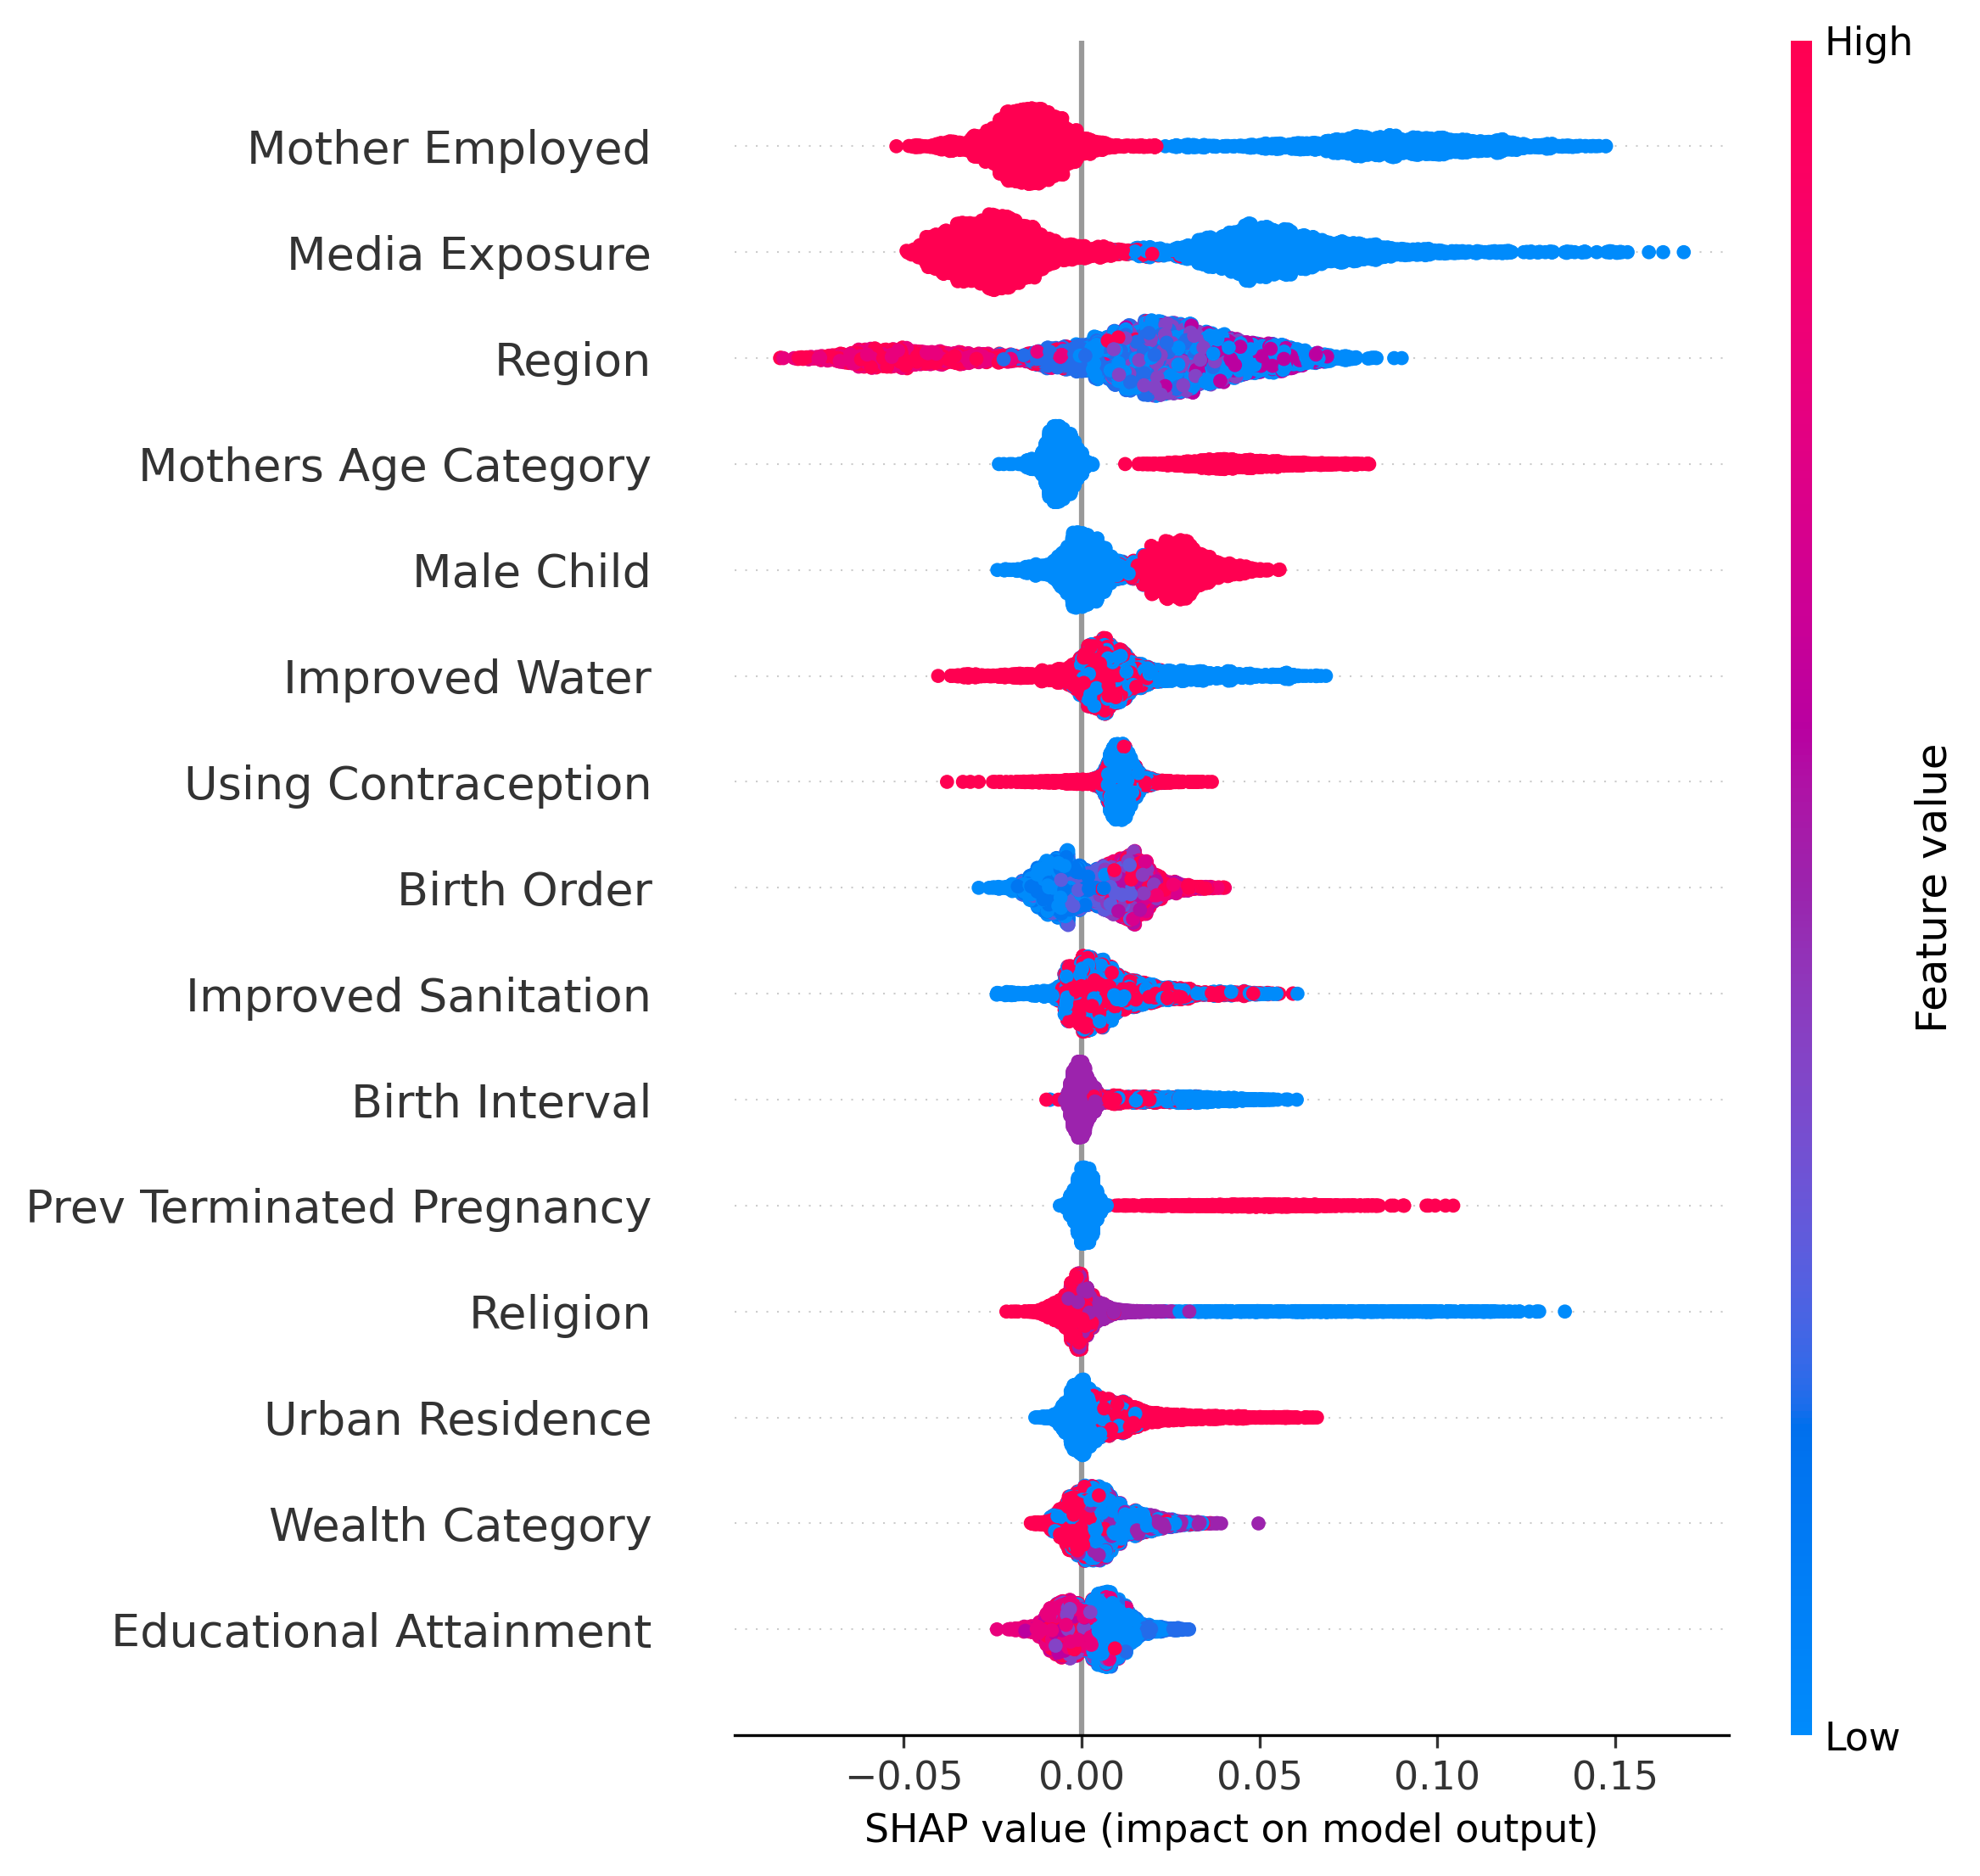

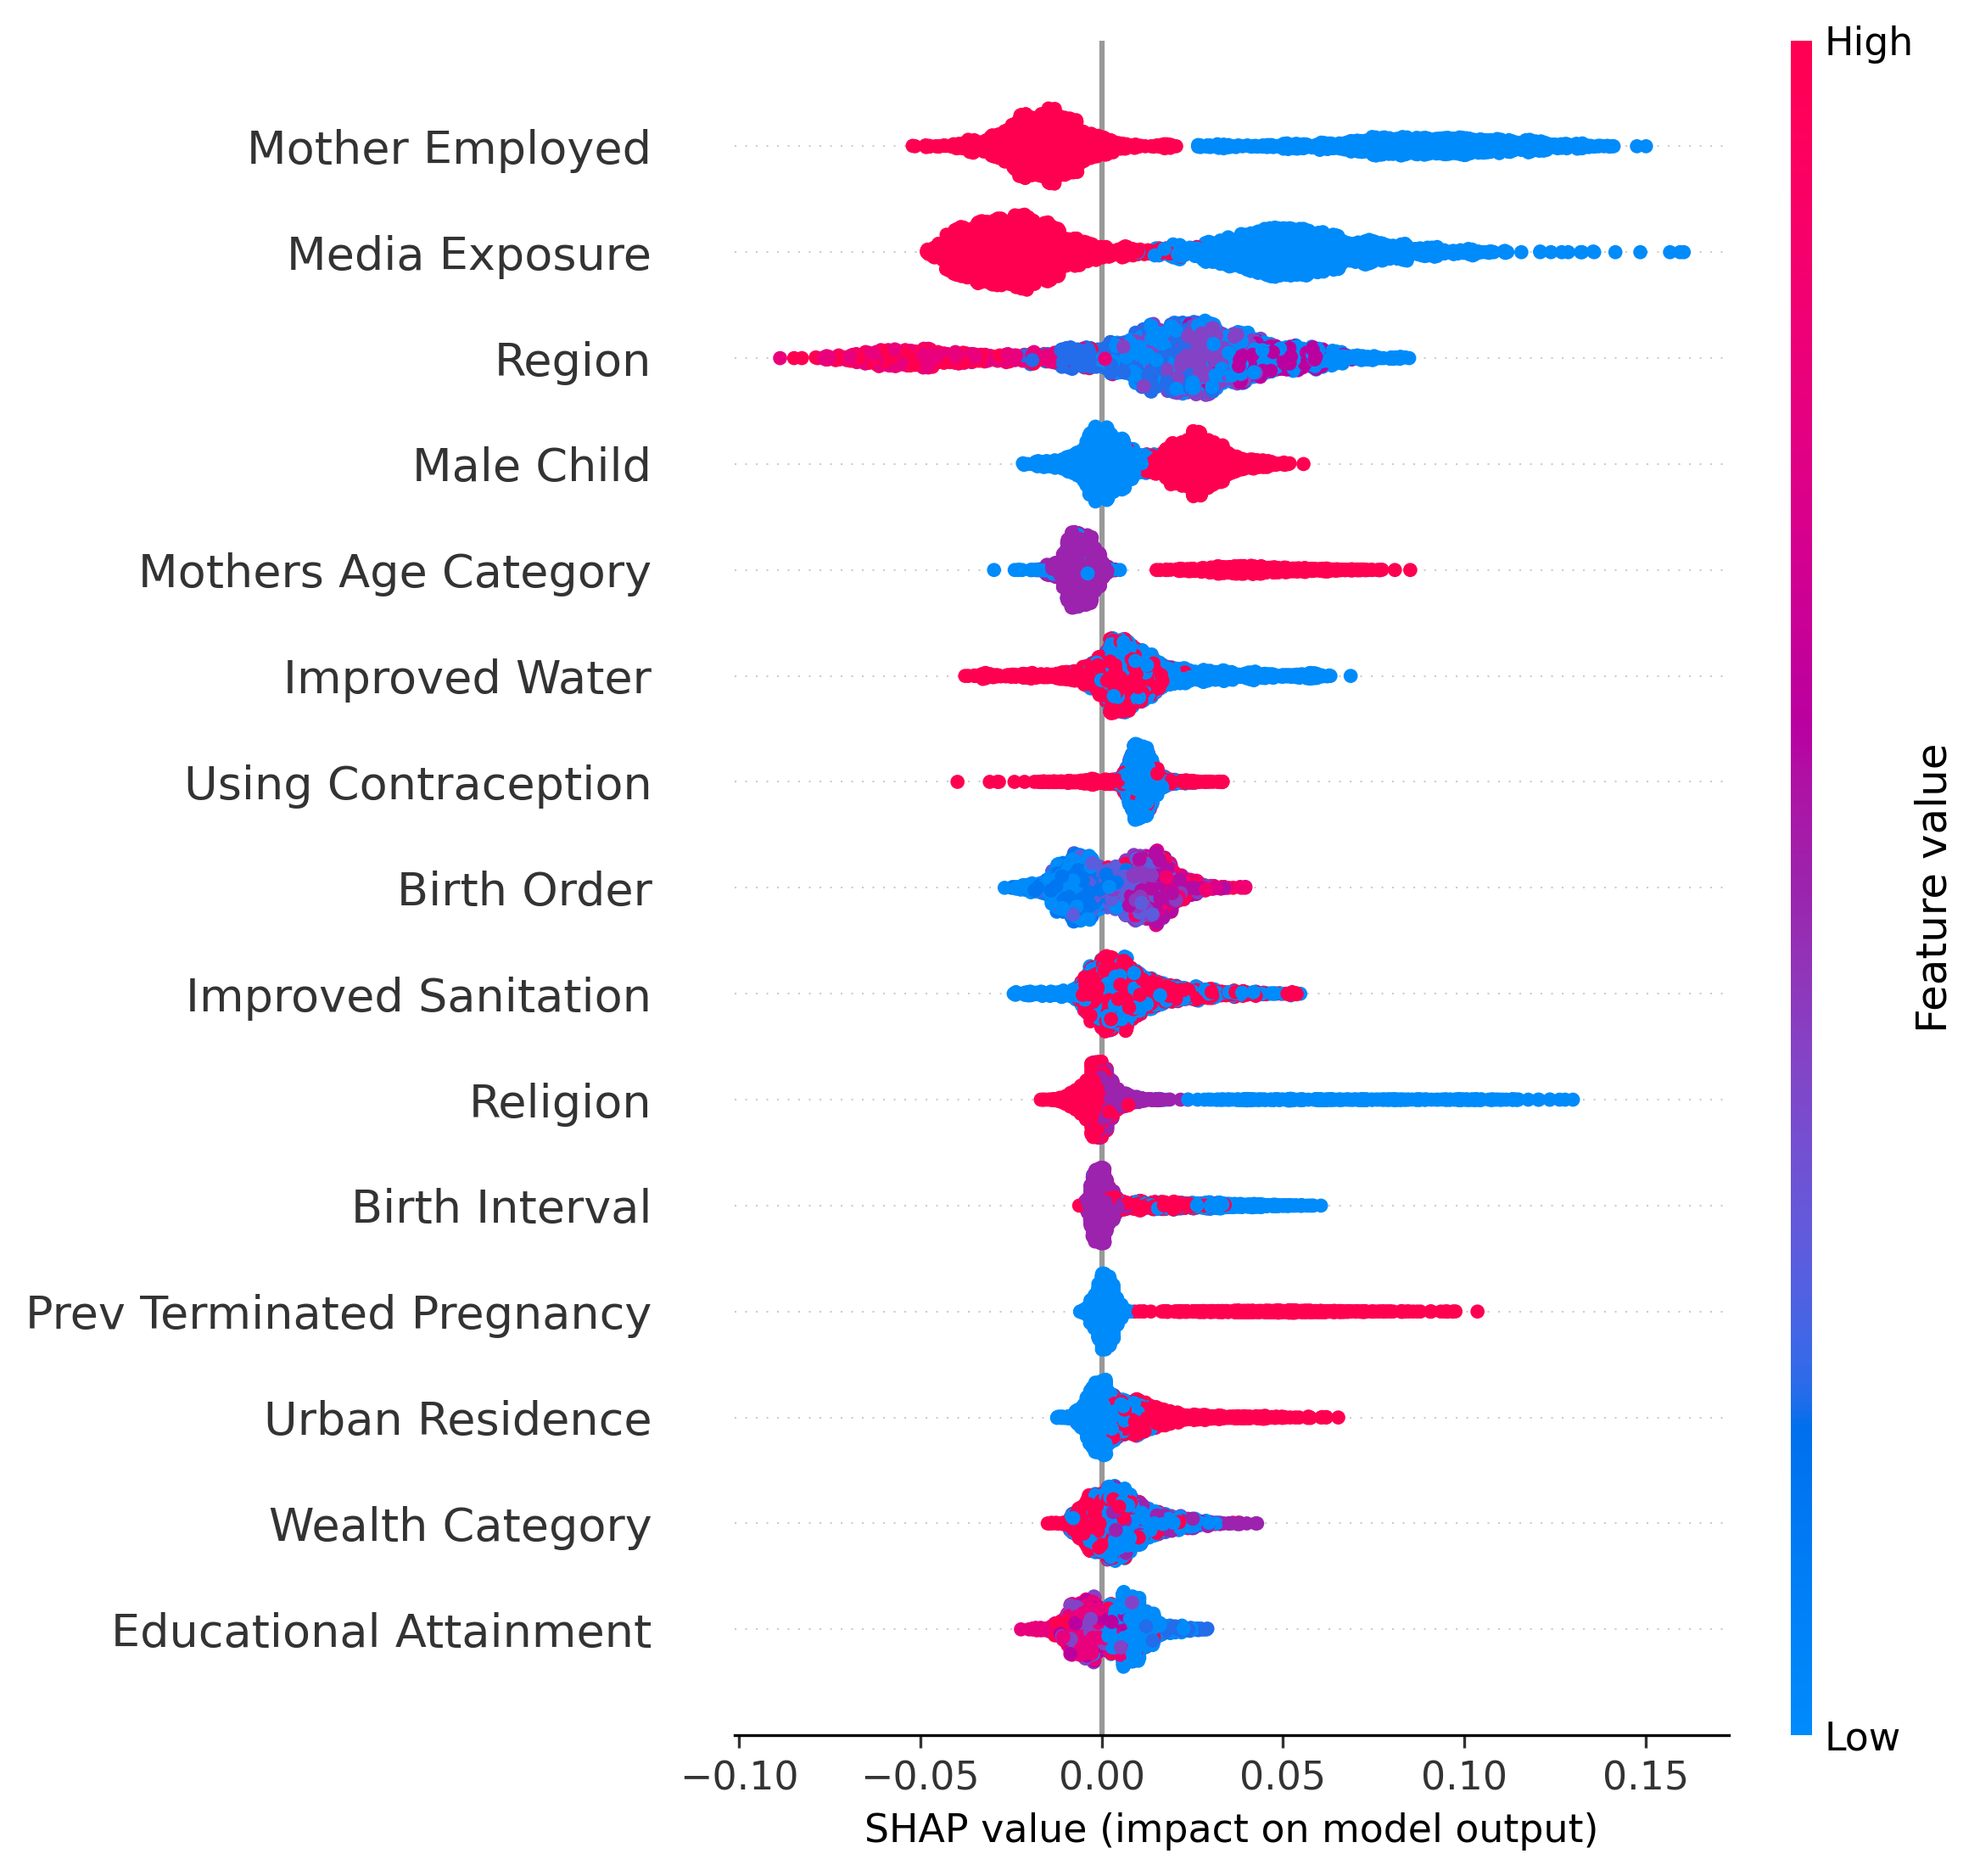

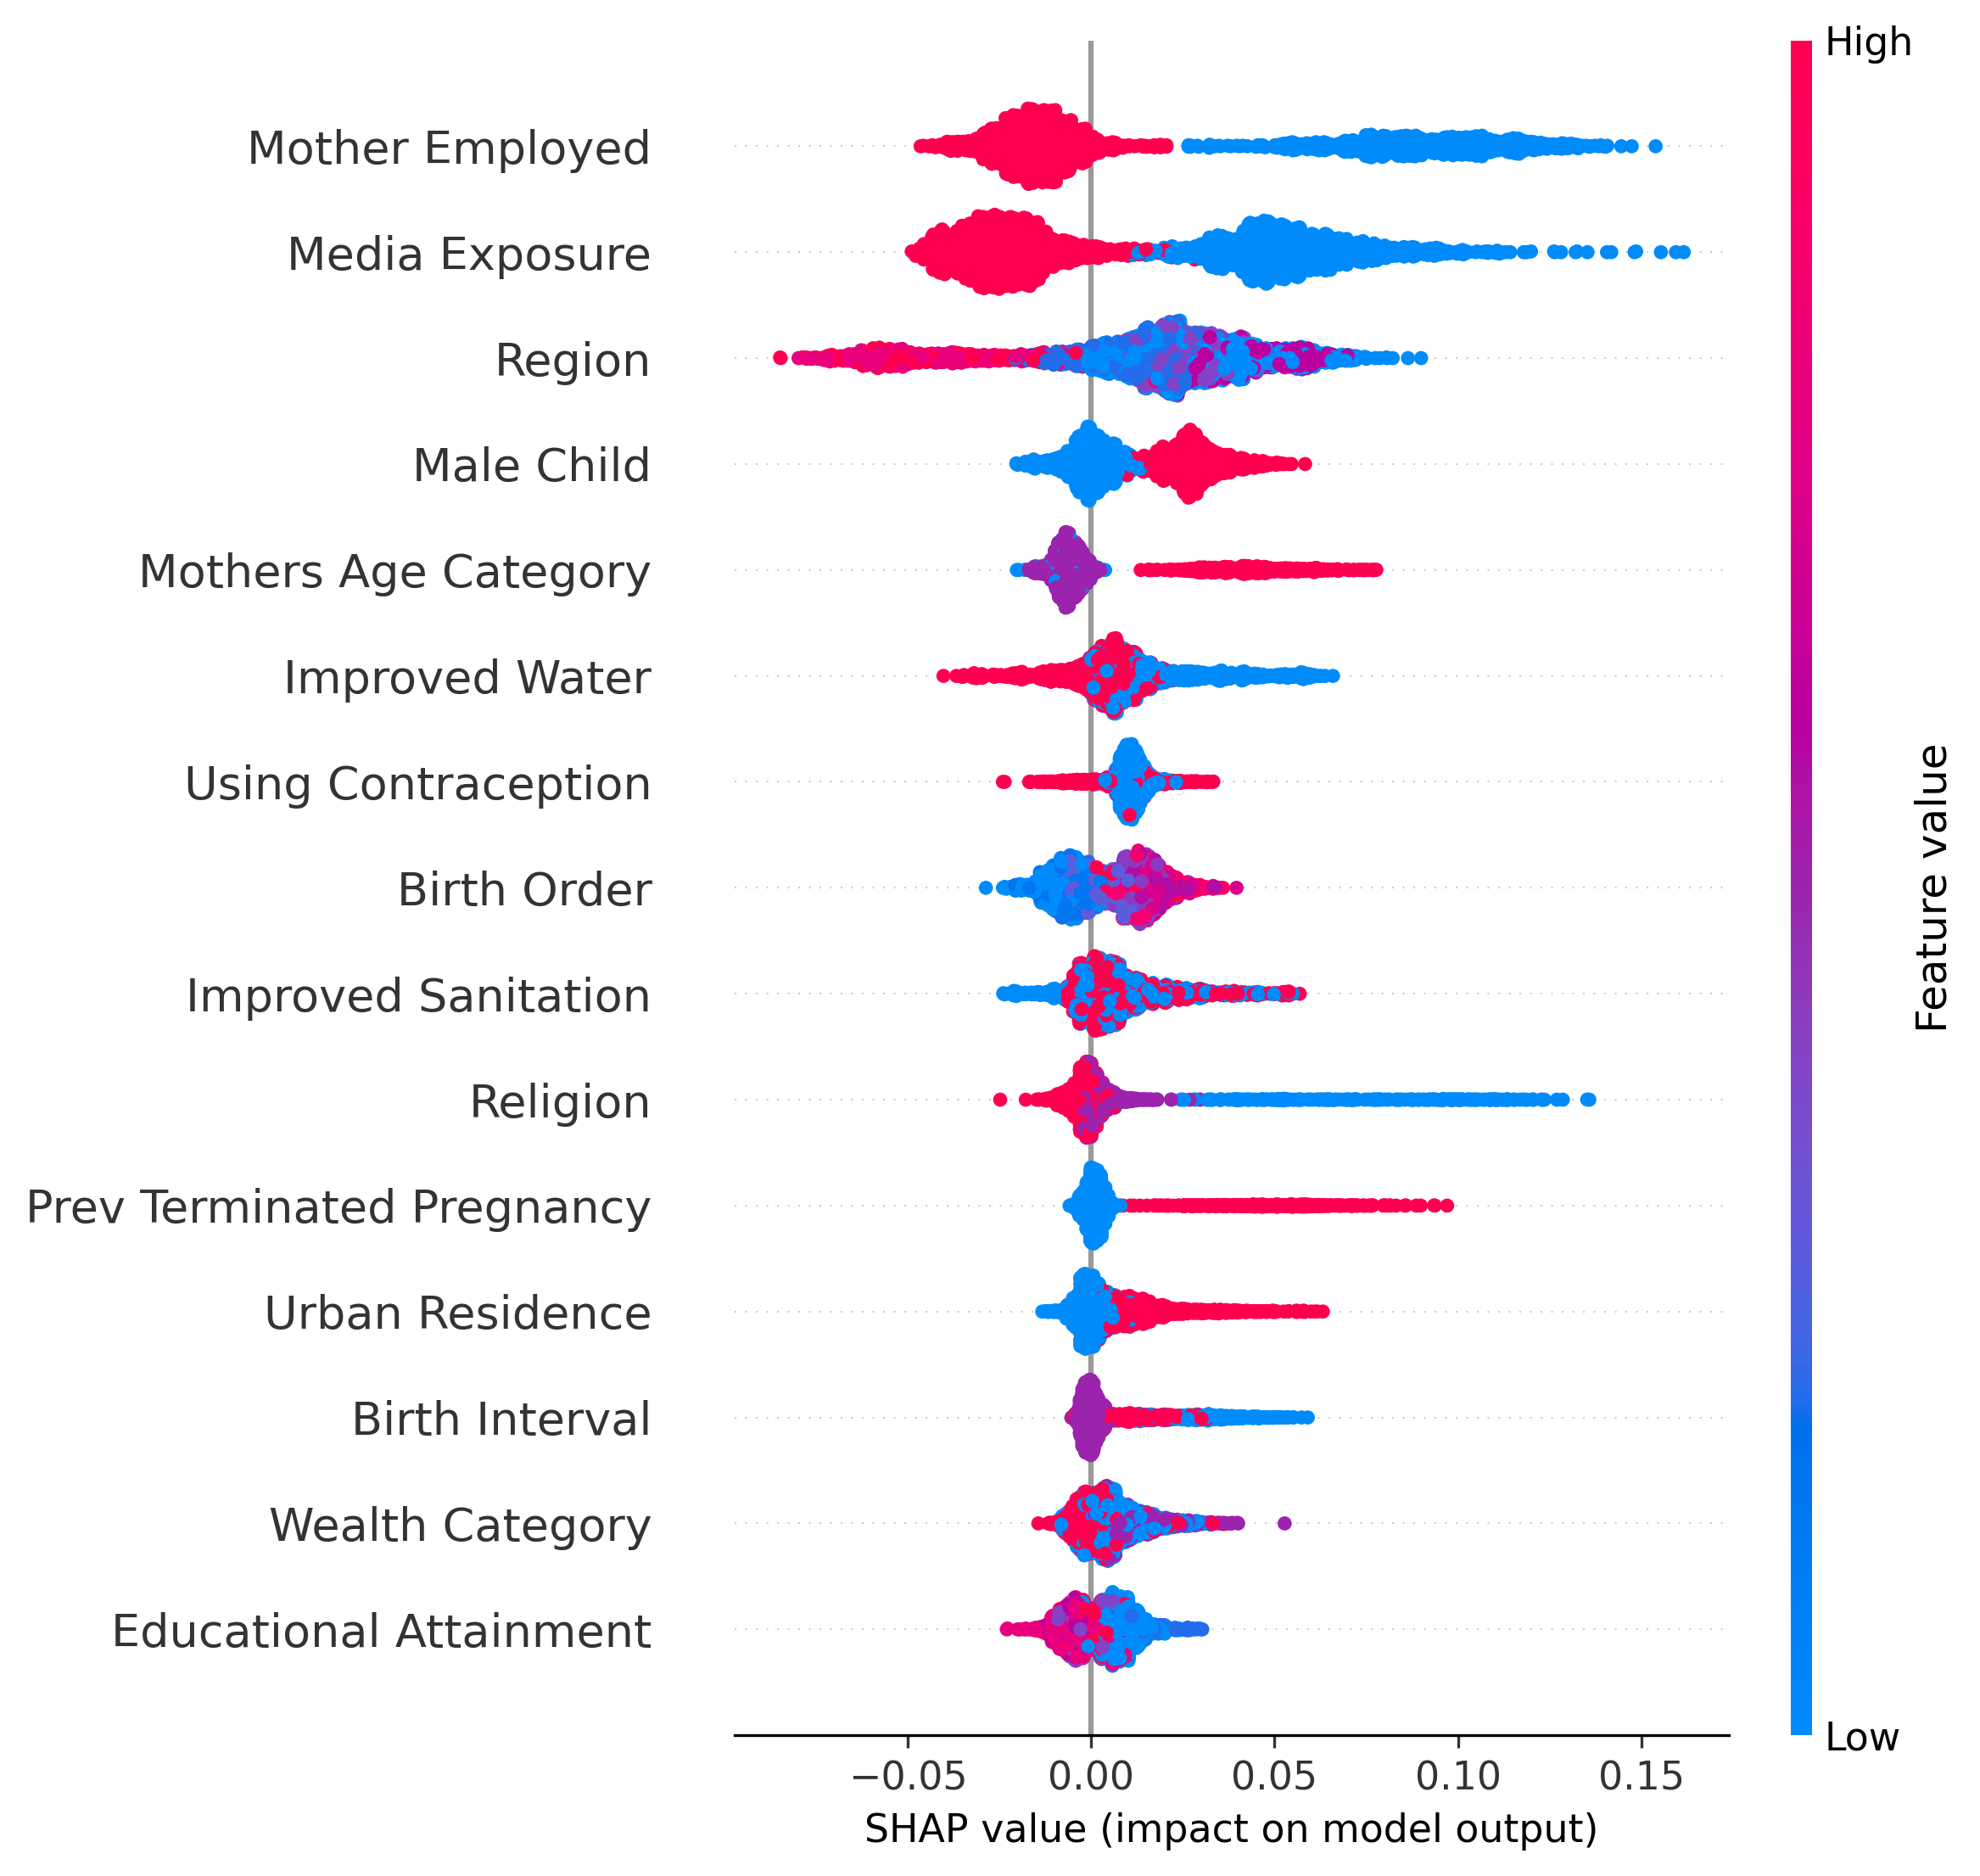

In [11]:
# FIGURE 8: SHAP Beeswarm (Random Forest — one per outcome)
for outcome in OUTCOMES:
    rf_model  = all_trained[outcome]["Random Forest"]
    Xte_shap  = all_splits[outcome]["X_test_raw"]
    explainer = shap.TreeExplainer(rf_model)
    sv        = explainer.shap_values(Xte_shap)
    if isinstance(sv, list):  sv = sv[1]
    elif sv.ndim == 3:        sv = sv[:,:,1]

    plt.figure(figsize=(9, 8))
    shap.summary_plot(sv, Xte_shap,
                      feature_names=renamed_cols,
                      show=False, max_display=15)
    ax = plt.gca()
    ax.set_xlabel("SHAP value (impact on model output)",
                  fontsize=11)
    ax.set_title("")
    plt.tight_layout()

    safe = outcome.replace("_","")
    plt.show()